# 1.Generate peptides and features for GraphNovo test dataset

In [1]:
import torch

import os
import re
import yaml
import random
import numpy as np
from tqdm import tqdm
from pyteomics import mgf
from torch.utils.data import Dataset, DataLoader
from model import Spec2Pep
from FDR import *

In [4]:
conf_path = 'config_xNovo_DDA.yaml'
with open(conf_path) as f:
    config = yaml.safe_load(f)

if config["random_seed"] is not None:
    random.seed(config["random_seed"])
    torch.manual_seed(config["random_seed"])
    
# load model
config['modelname'] = 'MassIVE_KB_trained_xNovo_DDA.pth'
config['mgf_file'] = 'GraphNovo_test_dst/'
config['train_mask_ratio'] = 0.0
config['use_by_mask'] = False
model = Spec2Pep(
    dim_model=config["dim_model"],
    n_head=config["n_head"],
    dim_feedforward=config["dim_feedforward"],
    n_layers=config["n_layers"],
    dropout=config["dropout"],
    dim_intensity=config["dim_intensity"],
    max_length=config["max_length"],
    residues=config["residues"],
    max_charge=config["max_charge"],
    use_by_mask=config['use_by_mask'],
    train_mask_ratio=config['train_mask_ratio'],
    train_signal=config['train_signal'],
    )
device = 'cuda:0'
model.load_state_dict(torch.load(config['modelname'], map_location=device)['state_dict'], strict=False)
model.to(device)
model.eval()
print(True)

True


In [5]:
species_list = ['A_Thaliana', 'C_Elegans', 'E_Coli']
for species in species_list:
    # load test dataset
    config['valid_species'] = species
    test_dst = ValidSpectrumDataset(config)
    val_loader = DataLoader(test_dst, batch_size=256, shuffle=False, 
                            num_workers=0, collate_fn=prepare_batch, 
                            drop_last=False)
    
    # de novo peptide sequencing and extract target-decoy features
    target_features, deocy_feature = denovo_and_evaluate_psm(model, val_loader, top_k=10, attn_type='max', device=device)
    target_df = convert_results_to_csv(target_features)
    decoy_df = convert_results_to_csv(deocy_feature)
    target_df.to_csv(f'db_features/target_{species}.csv', index=False)
    decoy_df.to_csv(f'db_features/decoy_{species}.csv', index=False)

  0%|          | 0/49 [00:00<?, ?it/s]/code/xNovo_DDA_github/pyteomics_master/pyteomics/auxiliary/structures.py:139: UserWarning: Could not parse ion string: noise (Malformed ion string, must match the regex '([abcxyz]\\d+(\\-H2O|\\-NH3)?)([\\+|-]\\d+)')
  warnings.warn('Could not parse ion string: {} ({})'.format(ion_text, e.args[0]))
  2%|▏         | 1/49 [00:07<05:43,  7.15s/it]/opt/conda/lib/python3.8/site-packages/scipy/stats/stats.py:4264: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
100%|██████████| 49/49 [03:21<00:00,  4.11s/it]


# 2.Dual-level CCT QC

In [1]:
import torch

import os
import re
import yaml
import random
import numpy as np
from tqdm import tqdm
from pyteomics import mgf
from torch.utils.data import Dataset, DataLoader
from model import Spec2Pep
from FDR import *

In [2]:
fdr_threshold = 0.05
db_features_dir = 'db_features/'
names = os.listdir(db_features_dir)
names = [name[7:-4] for name in names if 'target' in name]
names

['A_Thaliana', 'E_Coli', 'C_Elegans']

In [3]:
# load target-decoy features
decoy_file, target_file = [], []
with tqdm(total=len(names)) as pbar:
    psmid_num = 0
    for name in names:
        if os.path.exists(os.path.join(db_features_dir, f'decoy_{name}.csv')):
            _decoy_file = pd.read_csv(os.path.join(db_features_dir, f'decoy_{name}.csv'), sep=',')
            _decoy_file['sample'] = name
            decoy_file.append(_decoy_file)
            _target_file = pd.read_csv(os.path.join(db_features_dir, f'target_{name}.csv'), sep=',')
            _target_file['sample'] = name
            target_file.append(_target_file)
            print(len(_decoy_file))
            print(len(_target_file))
            pbar.update(1)
# concat all three species because the number of PSMs is small.            
decoy_file = pd.concat(decoy_file, ignore_index=True).drop(columns=['target_bool'])
target_file = pd.concat(target_file, ignore_index=True)
print(len(decoy_file), len(target_file))

 33%|███▎      | 1/3 [00:00<00:00,  4.19it/s]

12416
12416


 67%|██████▋   | 2/3 [00:00<00:00,  4.32it/s]

12452
12452


100%|██████████| 3/3 [00:00<00:00,  4.28it/s]

12498
12498
37366 37366


In [4]:
decoy_file = pd.merge(decoy_file, target_file[['sequence', 'spectrum_idx', 'target_bool', 'psm_id']], on=['sequence', 'spectrum_idx', 'psm_id'], how='left')
db_decoy_file = decoy_file.dropna().drop_duplicates().reset_index(drop=True)
db_target_file = target_file.dropna().reset_index(drop=True)
print(len(db_decoy_file), len(db_target_file))

36887 37321


In [5]:
db_sample = db_target_file['sample'].tolist() + db_decoy_file['sample'].tolist()
db_target_bools, db_target_seqs, db_target_spec_idxs, db_target_psm_ids, db_target_aa_confidence, db_target_features = convert_csv_to_dict(db_target_file.drop(columns=['sample']))
db_decoy_bools, db_decoy_seqs, db_decoy_spec_idxs, db_decoy_psm_ids, db_decoy_aa_confidence, db_decoy_features = convert_csv_to_dict(db_decoy_file.drop(columns=['sample'])) 

In [6]:
print(len(db_target_seqs), len(db_decoy_seqs))

37321 36887


In [7]:
sum(db_decoy_bools)

27087

## 2.1 CCT-PSM QC

In [8]:
# construct PSM-level training set and test set of scoring models
feature_name = db_target_features[0].keys()
X_psm = pd.DataFrame(db_target_features + db_decoy_features).to_numpy().tolist()
y_psm_relax = db_target_bools + [False for _ in range(len(db_decoy_bools))]
y_psm_strict = db_target_bools + db_decoy_bools

In [9]:
name = 'xNovo_massive'
device = 'cuda:0'
ckpt_path_relax = f'MLP_model/{name}_psm_relax.pt'
ckpt_path_strict = f'MLP_model/{name}_psm_strict.pt'
print(ckpt_path_relax, ckpt_path_strict)
# we do not fix random seed, if need to retrain the scoring model, the results may be differen slightly
# model_psm_relax = train_mlp(np.array(X_psm), y_psm_relax, lr=1e-3, dropout=0.0, epochs=50, batch_size=1024, device='cuda:0', ckpt_path=ckpt_path_relax)
# model_psm_strict = train_mlp(np.array(X_psm), y_psm_strict, lr=1e-3, dropout=0.0, epochs=50, batch_size=1024, device='cuda:0', ckpt_path=ckpt_path_strict)

MLP_model/xNovo_massive_psm_relax.pt MLP_model/xNovo_massive_psm_strict.pt


In [10]:
scores_psm_relax = test_mlp(np.array(X_psm), y_psm_relax, ckpt_path=ckpt_path_relax)
scores_psm_strict = test_mlp(np.array(X_psm), y_psm_strict, ckpt_path=ckpt_path_strict)

100%|██████████| 290/290 [00:00<00:00, 351.25it/s]



Final classification report (Val):
              precision    recall  f1-score   support

         0.0       0.94      0.93      0.93     46723
         1.0       0.89      0.89      0.89     27485

    accuracy                           0.92     74208
   macro avg       0.91      0.91      0.91     74208
weighted avg       0.92      0.92      0.92     74208



100%|██████████| 290/290 [00:00<00:00, 393.60it/s]



Final classification report (Val):
              precision    recall  f1-score   support

         0.0       0.94      0.75      0.84     19636
         1.0       0.92      0.98      0.95     54572

    accuracy                           0.92     74208
   macro avg       0.93      0.87      0.89     74208
weighted avg       0.92      0.92      0.92     74208



In [11]:
df_psm = pd.DataFrame(X_psm, columns=feature_name)
df_psm['is_decoy'] = [False for _ in range(len(db_target_bools))] + \
                 [True for _ in range(len(db_decoy_bools))]
df_psm['class'] = db_target_bools + [False for _ in range(len(db_decoy_bools))]
df_psm['denovo_label'] = db_target_bools + db_decoy_bools
df_psm['psm_score'] = 0.5 * (scores_psm_relax+scores_psm_strict)
df_psm['psm_score_relax'] = scores_psm_relax
df_psm['psm_score_strict'] = scores_psm_strict
df_psm['sequence'] = db_target_seqs + [''.join(list(reversed(re.split(r"(?<=.)(?=[A-Z])", seq)))) for seq in db_decoy_seqs]
df_psm['spectrum_idx'] = db_target_spec_idxs + db_decoy_spec_idxs
df_psm['psm_id'] = db_target_psm_ids + db_decoy_psm_ids 
df_psm['sample'] = db_sample
df_sorted_psm = calculate_fdr(df_psm.copy(), score_name='psm_score')

In [12]:
df_sorted_psm, gamma, conservative_point, optimal_idx, conservative_interval = gamma_fdr(df_sorted_psm)
print(gamma, conservative_point, optimal_idx, conservative_interval)

conservative start point: 0.0442, target fdr: 0.0500, start idx: 25136
according to Adjustment-factor theorem: gamma=0.8254 (nearby target fdr)
conservative interval: interval[0.0502, 0.2636], gamma=0.8254
0.8254071661237785 0.050187709938747285 26839 [0.050187709938747285, 0.2635513517858578]


In [13]:
# strict scoring model
df_psm_strict = calculate_fdr(df_psm, score_name='psm_score_strict')
# relaxed scoring model
df_psm_relax = calculate_fdr(df_psm, score_name='psm_score_relax')
# relaxed-adjusted scoring model
df_psm_relax_adj, psm_relax_adj_best_gamma, psm_relax_adj_true_fdr, psm_relax_adj_optimal_idx, psm_relax_adj_best_interval = \
                    gamma_fdr(df_psm_relax.copy(), fdr_thresh=0.05)
# combined scoring model
df_psm_combined = calculate_fdr(df_psm, score_name='psm_score')
# combined scoring model
df_psm_adj, psm_adj_best_gamma, psm_adj_true_fdr, psm_adj_optimal_idx, psm_adj_best_interval = \
                    gamma_fdr(df_psm_combined.copy(), fdr_thresh=0.05)  # 你已有的函数

# calculate cross marker of FDR curve with y=x
psm_fdr_strict, psm_score_strict, psm_true_strict = get_corss_point_fdr_curve(df_psm_strict, score_name='psm_score_strict')
psm_fdr_relax, psm_score_relax, psm_true_relax = get_corss_point_fdr_curve(df_psm_relax, score_name='psm_score_relax')
psm_fdr_relax_adj, psm_score_relax_adj, psm_true_relax_adj = get_corss_point_fdr_curve(df_psm_relax_adj, est_fdr_key='estimated_fdr_update',
                                                                                          score_name='psm_score_relax')
psm_fdr_combined, psm_score_combined, psm_true_combined = get_corss_point_fdr_curve(df_psm_combined, score_name='psm_score')
psm_fdr_adj, psm_score_adj, psm_true_adj = get_corss_point_fdr_curve(df_psm_adj, est_fdr_key='estimated_fdr_update', 
                                                                        score_name='psm_score')
print(psm_fdr_strict, psm_fdr_relax, psm_fdr_relax_adj, psm_fdr_combined, psm_fdr_adj)
print(psm_score_strict, psm_score_relax, psm_score_relax_adj, psm_score_combined, psm_score_adj)
print(psm_true_strict, psm_true_relax, psm_true_relax_adj, psm_true_combined, psm_true_adj)

print(psm_relax_adj_best_gamma, psm_relax_adj_true_fdr, psm_relax_adj_optimal_idx, psm_relax_adj_best_interval)
print(psm_adj_best_gamma, psm_adj_true_fdr, psm_adj_optimal_idx, psm_adj_best_interval)

conservative start point: 0.0802, target fdr: 0.0500, start idx: 30061
according to Adjustment-factor theorem: gamma=2.0565 (nearby target fdr)
conservative interval: interval[0.0502, 0.2636], gamma=2.0565
conservative start point: 0.0442, target fdr: 0.0500, start idx: 25136
according to Adjustment-factor theorem: gamma=0.8254 (nearby target fdr)
conservative interval: interval[0.0502, 0.2636], gamma=0.8254
1.0 0.08016240882469189 0.050075285007528496 0.04419889502762431 0.050069156293222686
0.9999538660049438 0.36950069665908813 0.6827512979507446 0.7374387979507446 0.6901826858520508
0 25602 22077 23011 24035
2.056537102473498 0.0502473650247365 23810 [0.0502473650247365, 0.2635513517858578]
0.8254071661237785 0.050187709938747285 26839 [0.050187709938747285, 0.2635513517858578]


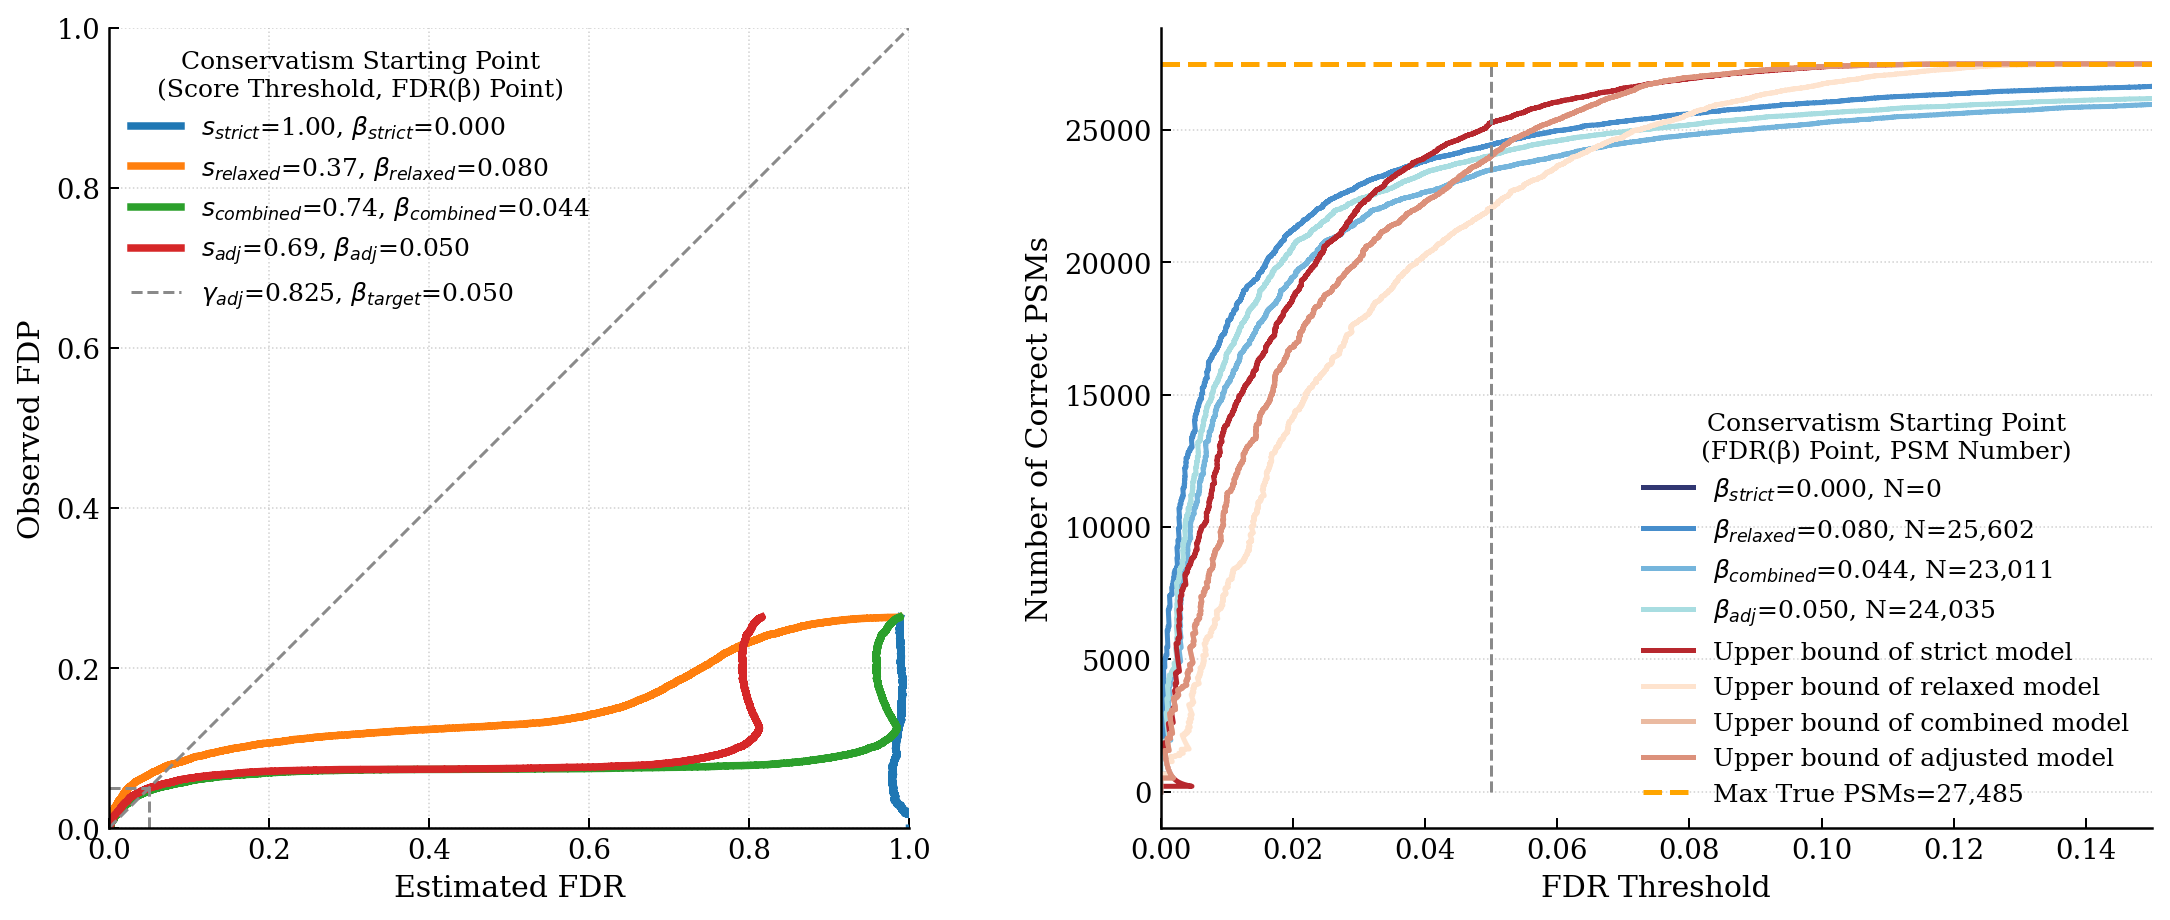

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
plt.rcParams.update({
    "figure.dpi": 180,
    "savefig.dpi": 600,
    "font.size": 8,
    "font.family": "serif",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 1.0,
    "axes.labelsize": 13,
    "axes.titlesize": 14,
    "legend.frameon": False,
    "legend.fontsize": 8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 4,
    "ytick.major.size": 4,
})

ideal_color = "#8a8a8a"
psm_fdr_strict = 0
fig, axs = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
# Panel A: Cumulative True FDR vs Cumulative Estimated FDR
axs[0].plot(
    df_psm_strict['estimated_fdr'].tolist(), df_psm_strict['observed_fdp'].tolist(),
    lw=3.0, label='$s_{\mathit{strict}}$='+f'{psm_score_strict:.2f}, '+'$β_{\mathit{strict}}$='+f'{psm_fdr_strict:.3f}'
)
axs[0].plot(
    df_psm_relax['estimated_fdr'].tolist(), df_psm_relax['observed_fdp'].tolist(),
    lw=3.0, label='$s_{\mathit{relaxed}}$='+f'{psm_score_relax:.2f}, '+'$β_{\mathit{relaxed}}$='+f'{psm_fdr_relax:.3f}'
)
axs[0].plot(
    df_psm_combined['estimated_fdr'].tolist(), df_psm_combined['observed_fdp'].tolist(),
    lw=3.0, label='$s_{\mathit{combined}}$='+f'{psm_score_combined:.2f}, '+'$β_{\mathit{combined}}$='+f'{psm_fdr_combined:.3f}'
)
axs[0].plot(
    df_psm_adj['estimated_fdr_update'].tolist(), df_psm_adj['observed_fdp'].tolist(),
    lw=3.0, label='$s_{\mathit{adj}}$='+f'{psm_score_adj:.2f}, '+'$β_{\mathit{adj}}$='+f'{psm_fdr_adj:.3f}'
)
axs[0].plot([0, 1.0], [0, 1.0], ls="--", lw=1.2, color=ideal_color, label='$γ_{\mathit{adj}}$='+f'{psm_adj_best_gamma:.3f}, '+'$β_{\mathit{target}}$='+f'{0.05:.3f}')
axs[0].plot([0, 0.05], [0.05, 0.05], ls="dashed", lw=1.2, color=ideal_color)
axs[0].plot([0.05, 0.05], [0, 0.05], ls="dashed", lw=1.2, color=ideal_color)

axs[0].set_xlim(0, 1)
axs[0].set_ylim(0, 1)
axs[0].tick_params(labelsize=11)
axs[0].set_aspect('equal', adjustable='box') 
axs[0].set_xlabel("Estimated FDR", fontsize=12)
axs[0].set_ylabel("Observed FDP", fontsize=12)
axs[0].grid(axis='both', linestyle=':', linewidth=0.6, alpha=0.6)
legend_obj = axs[0].legend(title='Conservatism Starting Point\n(Score Threshold, FDR(β) Point)', 
              loc="best", ncol=1, fontsize=10, frameon=False, title_fontsize=10)
legend_obj.get_title().set_horizontalalignment('center')

# Panel B: Cumulative counts vs Cumulative Estimated FDR
axs[1].plot(df_psm_strict['estimated_fdr'].tolist(), df_psm_strict['cum_true'].tolist(),
            label='$β_{\mathit{strict}}$='+f'{psm_fdr_strict:.3f}, N={psm_true_strict:,}', lw=2.0, color='#313772')
axs[1].plot(df_psm_relax['estimated_fdr'].tolist(), df_psm_relax['cum_true'].tolist(),
            label='$β_{\mathit{relaxed}}$='+f'{psm_fdr_relax:.3f}, N={psm_true_relax:,}', lw=2.0, color='#478ecc')
axs[1].plot(df_psm_combined['estimated_fdr'].tolist(), df_psm_combined['cum_true'].tolist(),
            label='$β_{\mathit{combined}}$='+f'{psm_fdr_combined:.3f}, N={psm_true_combined:,}', lw=2.0, color='#75b5dc')
axs[1].plot(df_psm_adj['estimated_fdr_update'].tolist(), df_psm_adj['cum_true'].tolist(),
            label='$β_{\mathit{adj}}$='+f'{psm_fdr_adj:.3f}, N={psm_true_adj:,}', lw=2.0, color='#a8dde1')


axs[1].plot(df_psm_strict['observed_fdp'].tolist(), df_psm_strict['cum_true'].tolist(),
            label='Upper bound of strict model', lw=2.0, color='#b7282e')
axs[1].plot(df_psm_relax['observed_fdp'].tolist(), df_psm_relax['cum_true'].tolist(),
            label='Upper bound of relaxed model', lw=2.0, color='#fee3ce')
axs[1].plot(df_psm_combined['observed_fdp'].tolist(), df_psm_combined['cum_true'].tolist(),
            label='Upper bound of combined model', lw=2.0, color='#eabaa1')
axs[1].plot(df_psm_adj['observed_fdp'].tolist(), df_psm_adj['cum_true'].tolist(),
            label='Upper bound of adjusted model', lw=2.0, color='#dc917b')

axs[1].plot([0.05, 0.05], [0, max(df_sorted_psm['cum_true'].tolist())], ls="dashed", lw=1.2, color=ideal_color)
N_max = max(df_psm_strict['cum_true'])
axs[1].plot([0.0, 0.5], [max(df_sorted_psm['cum_true'].tolist()), max(df_sorted_psm['cum_true'].tolist())], ls="--", 
            label=f'Max True PSMs={N_max:,}', lw=2.0, color='orange')

axs[1].set_xlim(0, 0.15)
axs[1].tick_params(labelsize=11)
axs[0].set_aspect('equal', adjustable='box') 
axs[1].set_xlabel("FDR Threshold", fontsize=12)
axs[1].set_ylabel("Number of Correct PSMs", fontsize=12)
axs[1].grid(axis='y', linestyle=':', linewidth=0.6, alpha=0.6)
legend_obj2 = axs[1].legend(title='Conservatism Starting Point\n(FDR(β) Point, PSM Number)', loc="best", ncol=1, fontsize=10,
                           frameon=False, title_fontsize=10)
legend_obj2.get_title().set_horizontalalignment('center')
plt.show()

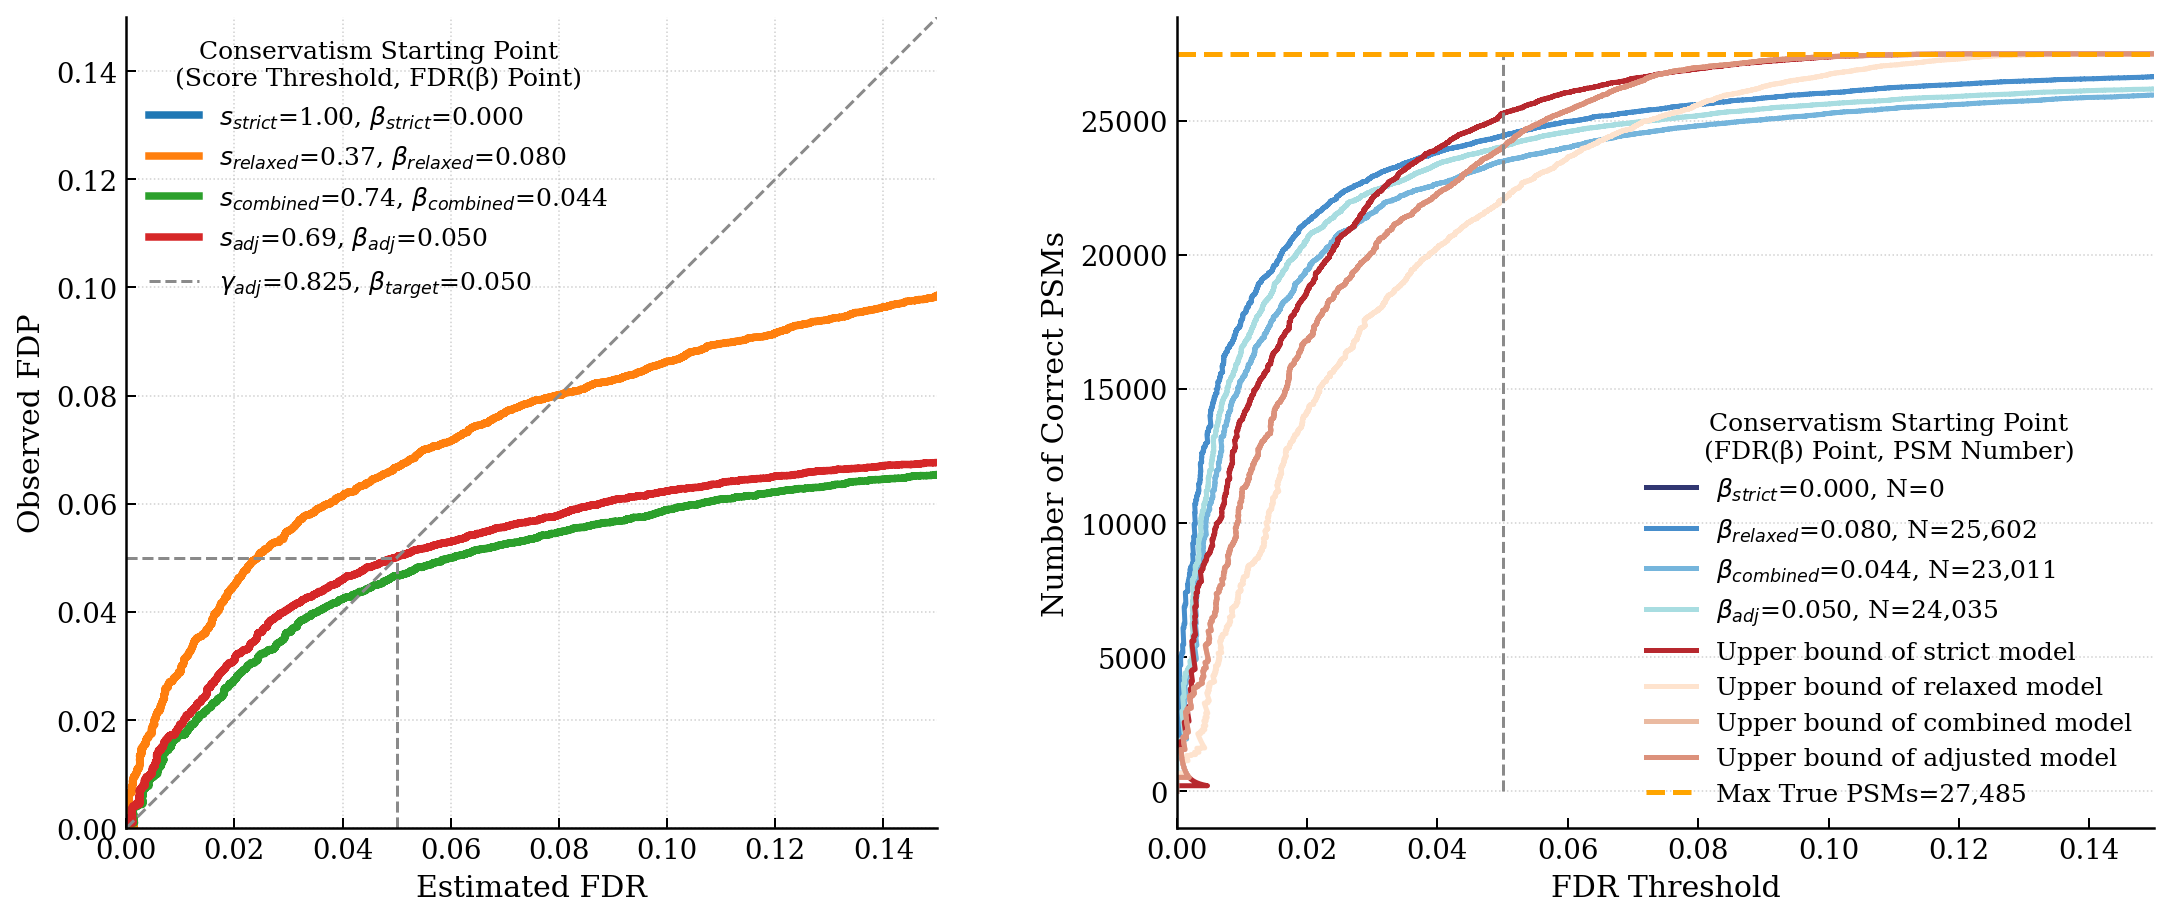

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
plt.rcParams.update({
    "figure.dpi": 180,
    "savefig.dpi": 600,
    "font.size": 8,
    "font.family": "serif",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 1.0,
    "axes.labelsize": 13,
    "axes.titlesize": 14,
    "legend.frameon": False,
    "legend.fontsize": 8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 4,
    "ytick.major.size": 4,
})

ideal_color = "#8a8a8a"
psm_fdr_strict = 0
fig, axs = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
# Panel A: Cumulative True FDR vs Cumulative Estimated FDR
axs[0].plot(
    df_psm_strict['estimated_fdr'].tolist(), df_psm_strict['observed_fdp'].tolist(),
    lw=3.0, label='$s_{\mathit{strict}}$='+f'{psm_score_strict:.2f}, '+'$β_{\mathit{strict}}$='+f'{psm_fdr_strict:.3f}'
)
axs[0].plot(
    df_psm_relax['estimated_fdr'].tolist(), df_psm_relax['observed_fdp'].tolist(),
    lw=3.0, label='$s_{\mathit{relaxed}}$='+f'{psm_score_relax:.2f}, '+'$β_{\mathit{relaxed}}$='+f'{psm_fdr_relax:.3f}'
)
axs[0].plot(
    df_psm_combined['estimated_fdr'].tolist(), df_psm_combined['observed_fdp'].tolist(),
    lw=3.0, label='$s_{\mathit{combined}}$='+f'{psm_score_combined:.2f}, '+'$β_{\mathit{combined}}$='+f'{psm_fdr_combined:.3f}'
)
axs[0].plot(
    df_psm_adj['estimated_fdr_update'].tolist(), df_psm_adj['observed_fdp'].tolist(),
    lw=3.0, label='$s_{\mathit{adj}}$='+f'{psm_score_adj:.2f}, '+'$β_{\mathit{adj}}$='+f'{psm_fdr_adj:.3f}'
)
axs[0].plot([0, 0.15], [0, 0.15], ls="--", lw=1.2, color=ideal_color, label='$γ_{\mathit{adj}}$='+f'{psm_adj_best_gamma:.3f}, '+'$β_{\mathit{target}}$='+f'{0.05:.3f}')
axs[0].plot([0, 0.05], [0.05, 0.05], ls="dashed", lw=1.2, color=ideal_color)
axs[0].plot([0.05, 0.05], [0, 0.05], ls="dashed", lw=1.2, color=ideal_color)

axs[0].set_xlim(0, 0.15)
axs[0].set_ylim(0, 0.15)
axs[0].tick_params(labelsize=11)
axs[0].set_aspect('equal', adjustable='box') 
axs[0].set_xlabel("Estimated FDR", fontsize=12)
axs[0].set_ylabel("Observed FDP", fontsize=12)
axs[0].grid(axis='both', linestyle=':', linewidth=0.6, alpha=0.6)
legend_obj = axs[0].legend(title='Conservatism Starting Point\n(Score Threshold, FDR(β) Point)', 
              loc="best", ncol=1, fontsize=10, frameon=False, title_fontsize=10)
legend_obj.get_title().set_horizontalalignment('center')

# Panel B: Cumulative counts vs Cumulative Estimated FDR
axs[1].plot(df_psm_strict['estimated_fdr'].tolist(), df_psm_strict['cum_true'].tolist(),
            label='$β_{\mathit{strict}}$='+f'{psm_fdr_strict:.3f}, N={psm_true_strict:,}', lw=2.0, color='#313772')
axs[1].plot(df_psm_relax['estimated_fdr'].tolist(), df_psm_relax['cum_true'].tolist(),
            label='$β_{\mathit{relaxed}}$='+f'{psm_fdr_relax:.3f}, N={psm_true_relax:,}', lw=2.0, color='#478ecc')
axs[1].plot(df_psm_combined['estimated_fdr'].tolist(), df_psm_combined['cum_true'].tolist(),
            label='$β_{\mathit{combined}}$='+f'{psm_fdr_combined:.3f}, N={psm_true_combined:,}', lw=2.0, color='#75b5dc')
axs[1].plot(df_psm_adj['estimated_fdr_update'].tolist(), df_psm_adj['cum_true'].tolist(),
            label='$β_{\mathit{adj}}$='+f'{psm_fdr_adj:.3f}, N={psm_true_adj:,}', lw=2.0, color='#a8dde1')


axs[1].plot(df_psm_strict['observed_fdp'].tolist(), df_psm_strict['cum_true'].tolist(),
            label='Upper bound of strict model', lw=2.0, color='#b7282e')
axs[1].plot(df_psm_relax['observed_fdp'].tolist(), df_psm_relax['cum_true'].tolist(),
            label='Upper bound of relaxed model', lw=2.0, color='#fee3ce')
axs[1].plot(df_psm_combined['observed_fdp'].tolist(), df_psm_combined['cum_true'].tolist(),
            label='Upper bound of combined model', lw=2.0, color='#eabaa1')
axs[1].plot(df_psm_adj['observed_fdp'].tolist(), df_psm_adj['cum_true'].tolist(),
            label='Upper bound of adjusted model', lw=2.0, color='#dc917b')

axs[1].plot([0.05, 0.05], [0, max(df_sorted_psm['cum_true'].tolist())], ls="dashed", lw=1.2, color=ideal_color)
N_max = max(df_psm_strict['cum_true'])
axs[1].plot([0.0, 0.5], [max(df_sorted_psm['cum_true'].tolist()), max(df_sorted_psm['cum_true'].tolist())], ls="--", 
            label=f'Max True PSMs={N_max:,}', lw=2.0, color='orange')

axs[1].set_xlim(0, 0.15)
axs[1].tick_params(labelsize=11)
axs[0].set_aspect('equal', adjustable='box') 
axs[1].set_xlabel("FDR Threshold", fontsize=12)
axs[1].set_ylabel("Number of Correct PSMs", fontsize=12)
axs[1].grid(axis='y', linestyle=':', linewidth=0.6, alpha=0.6)
legend_obj2 = axs[1].legend(title='Conservatism Starting Point\n(FDR(β) Point, PSM Number)', loc="best", ncol=1, fontsize=10,
                           frameon=False, title_fontsize=10)
legend_obj2.get_title().set_horizontalalignment('center')
plt.show()

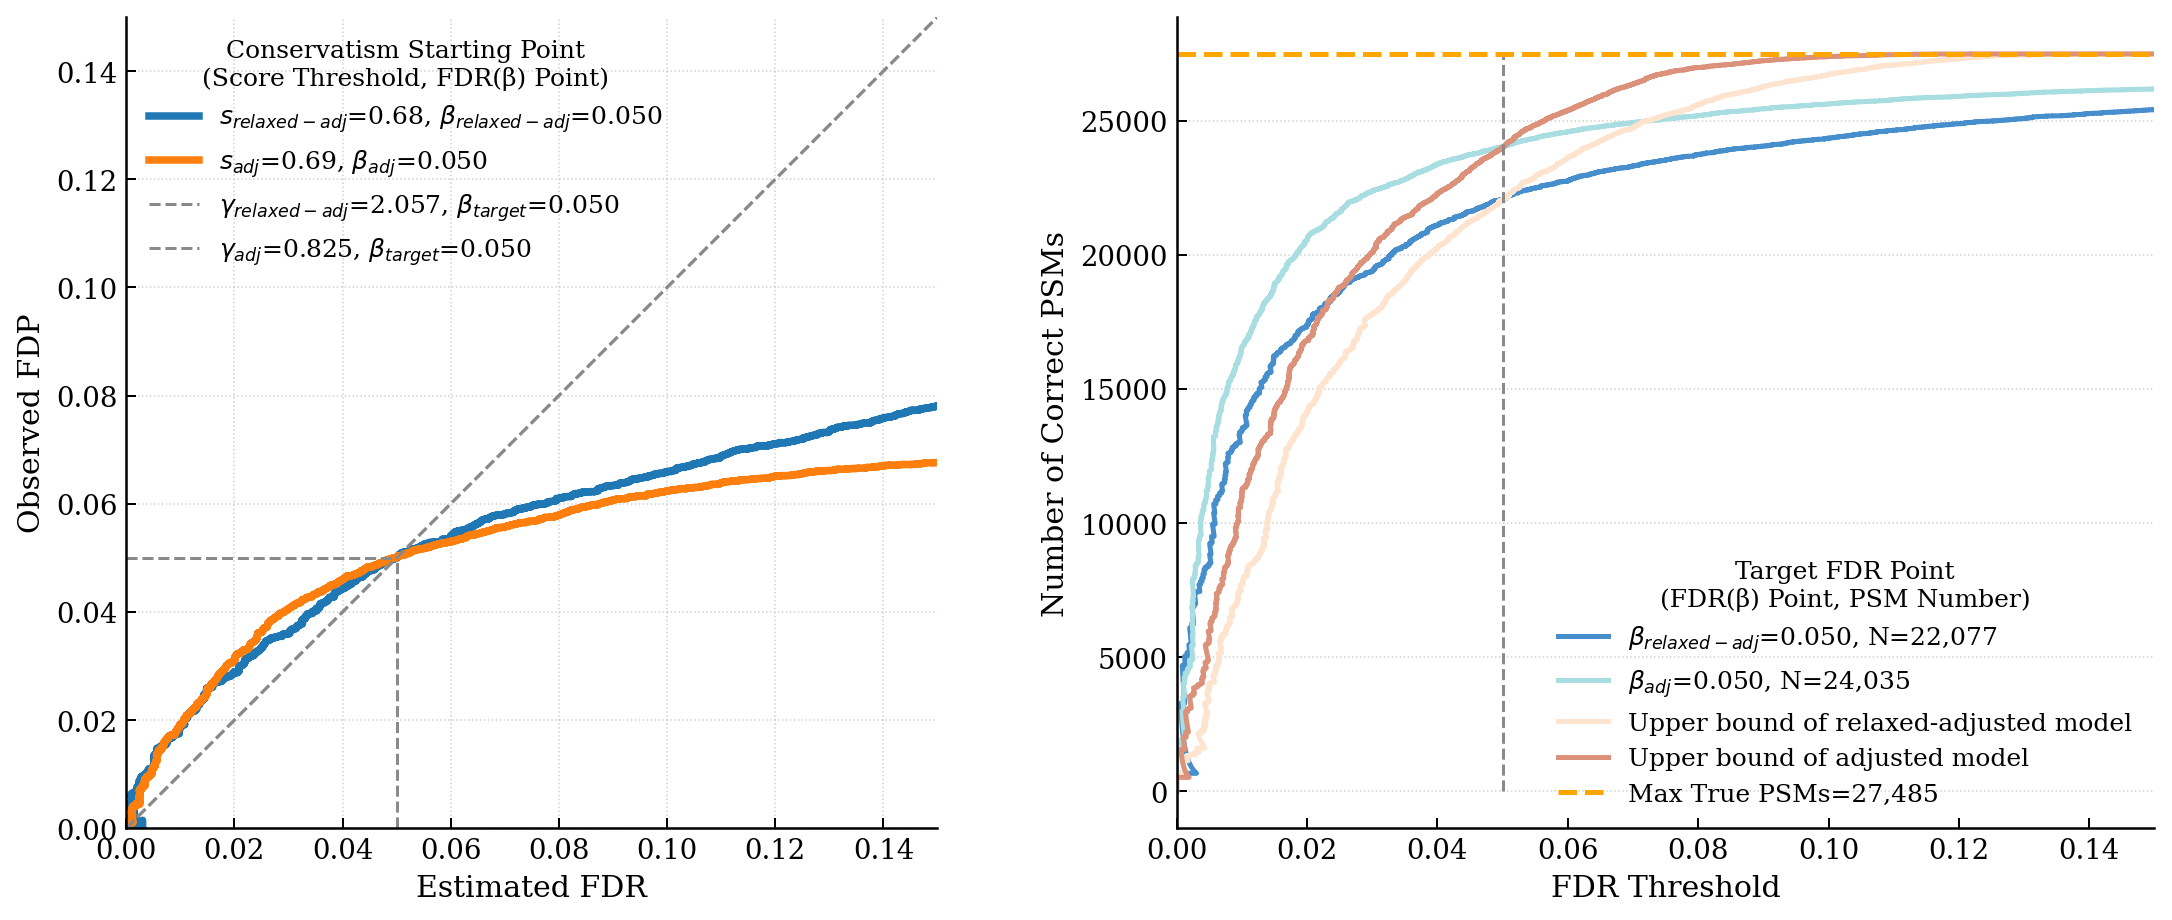

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
plt.rcParams.update({
    "figure.dpi": 180,
    "savefig.dpi": 600,
    "font.size": 8,
    "font.family": "serif",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 1.0,
    "axes.labelsize": 13,
    "axes.titlesize": 14,
    "legend.frameon": False,
    "legend.fontsize": 8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 4,
    "ytick.major.size": 4,
})

ideal_color = "#8a8a8a"

fig, axs = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
# Panel A: Cumulative True FDR vs Cumulative Estimated FDR
axs[0].plot(
    df_psm_relax_adj['estimated_fdr_update'].tolist(), df_psm_relax_adj['observed_fdp'].tolist(),
    lw=3.0, label='$s_{\mathit{relaxed-adj}}$='+f'{psm_score_relax_adj:.2f}, '+'$β_{\mathit{relaxed-adj}}$='+f'{psm_fdr_relax_adj:.3f}'
)
axs[0].plot(
    (df_psm_adj['estimated_fdr_update']).tolist(), df_psm_adj['observed_fdp'].tolist(),
    lw=3.0, label='$s_{\mathit{adj}}$='+f'{psm_score_adj:.2f}, '+'$β_{\mathit{adj}}$='+f'{psm_fdr_adj:.3f}'
)
axs[0].plot([0, 0.15], [0, 0.15], ls="--", lw=1.2, color=ideal_color, label='$γ_{\mathit{relaxed-adj}}$='+f'{psm_relax_adj_best_gamma:.3f}, '+'$β_{\mathit{target}}$='+f'{0.05:.3f}')
axs[0].plot([0, 0.15], [0, 0.15], ls="--", lw=1.2, color=ideal_color, label='$γ_{\mathit{adj}}$='+f'{psm_adj_best_gamma:.3f}, '+'$β_{\mathit{target}}$='+f'{0.05:.3f}')
axs[0].plot([0, 0.05], [0.05, 0.05], ls="dashed", lw=1.2, color=ideal_color)
axs[0].plot([0.05, 0.05], [0, 0.05], ls="dashed", lw=1.2, color=ideal_color)

axs[0].set_xlim(0, 0.15)
axs[0].set_ylim(0, 0.15)
axs[0].tick_params(labelsize=11)
axs[0].set_aspect('equal', adjustable='box') 
axs[0].set_xlabel("Estimated FDR", fontsize=12)
axs[0].set_ylabel("Observed FDP", fontsize=12)
axs[0].grid(axis='both', linestyle=':', linewidth=0.6, alpha=0.6)
legend_obj = axs[0].legend(title='Conservatism Starting Point\n(Score Threshold, FDR(β) Point)', 
              loc="upper left", ncol=1, fontsize=10, frameon=False, title_fontsize=10)
legend_obj.get_title().set_horizontalalignment('center')

# Panel B: Cumulative counts vs Cumulative Estimated FDR
axs[1].plot(df_psm_relax_adj['estimated_fdr_update'].tolist(), df_psm_relax_adj['cum_true'].tolist(),
            label='$β_{\mathit{relaxed-adj}}$='+f'{psm_fdr_relax_adj:.3f}, N={psm_true_relax_adj:,}', lw=2.0, color='#478ecc')
axs[1].plot((df_psm_adj['estimated_fdr_update']).tolist(), df_psm_adj['cum_true'].tolist(),
            label='$β_{\mathit{adj}}$='+f'{psm_fdr_adj:.3f}, N={psm_true_adj:,}', lw=2.0, color='#a8dde1')


axs[1].plot(df_psm_relax_adj['observed_fdp'].tolist(), df_psm_relax_adj['cum_true'].tolist(),
            label='Upper bound of relaxed-adjusted model', lw=2.0, color='#fee3ce')
axs[1].plot(df_psm_adj['observed_fdp'].tolist(), df_psm_adj['cum_true'].tolist(),
            label='Upper bound of adjusted model', lw=2.0, color='#dc917b')

axs[1].plot([0.05, 0.05], [0, max(df_sorted_psm['cum_true'].tolist())], ls="dashed", lw=1.2, color=ideal_color)
N_max = max(df_psm_strict['cum_true'])
axs[1].plot([0.0, 0.5], [max(df_sorted_psm['cum_true'].tolist()), max(df_sorted_psm['cum_true'].tolist())], ls="--", 
            label=f'Max True PSMs={N_max:,}', lw=2.0, color='orange')

axs[1].set_xlim(0, 0.15)
axs[1].tick_params(labelsize=11)
axs[0].set_aspect('equal', adjustable='box') 
axs[1].set_xlabel("FDR Threshold", fontsize=12)

axs[1].set_ylabel("Number of Correct PSMs", fontsize=12)
axs[1].grid(axis='y', linestyle=':', linewidth=0.6, alpha=0.6)
legend_obj2 = axs[1].legend(title='Target FDR Point\n(FDR(β) Point, PSM Number)', loc="best", ncol=1, fontsize=10,
                           frameon=False, title_fontsize=10)
legend_obj2.get_title().set_horizontalalignment('center')
plt.show()

27485 9836 9800 27087
27485 9836 9800


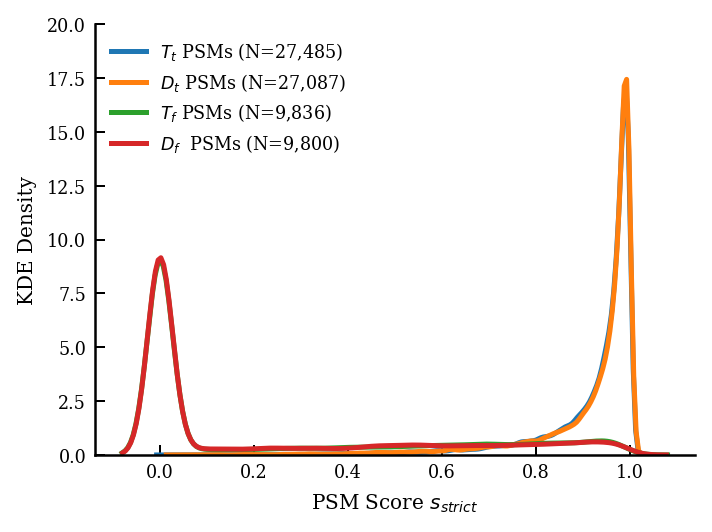

In [17]:
# PSM score distribution
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
scores_corr = df_sorted_psm[(df_sorted_psm['is_decoy'] == False) & (df_sorted_psm['denovo_label'] == 1)]['psm_score_strict'].to_numpy()
scores_false = df_sorted_psm[(df_sorted_psm['is_decoy'] == False) & (df_sorted_psm['denovo_label'] == 0)]['psm_score_strict'].to_numpy()
scores_decoy = df_sorted_psm[(df_sorted_psm['is_decoy'] == True) & (df_sorted_psm['denovo_label'] == 0)]['psm_score_strict'].to_numpy()
scores_decoy_true = df_sorted_psm[(df_sorted_psm['is_decoy'] == True) & (df_sorted_psm['denovo_label'] == 1)]['psm_score_strict'].to_numpy()
N_corr = len(scores_corr)
N_false = len(scores_false)
N_corr_d = len(scores_decoy)
N_false_d = len(scores_decoy_true)
print(len(scores_corr), len(scores_false), len(scores_decoy), len(scores_decoy_true))
plt.rcParams.update({
    "figure.dpi": 180,
    "savefig.dpi": 600,
    "font.size": 8,
    "font.family": "serif",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 1.0,
    "axes.labelsize": 10,
    "axes.titlesize": 14,
    "legend.frameon": False,
    "legend.fontsize": 8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 4,
    "ytick.major.size": 4,
})

print(len(scores_corr), len(scores_false), len(scores_decoy))
plt.figure(figsize=(4, 3))
sns.kdeplot(scores_corr, bw_adjust=0.5, label=f'$T_t$ PSMs (N={N_corr:,})', linewidth=2)
sns.kdeplot(scores_decoy_true, bw_adjust=0.5, label=f'$D_t$ PSMs (N={N_false_d:,})', linewidth=2)
sns.kdeplot(scores_false, bw_adjust=0.5, label=f'$T_f$ PSMs (N={N_false:,})', linewidth=2)
sns.kdeplot(scores_decoy, bw_adjust=0.5, label=f'$D_f$  PSMs (N={N_corr_d:,})', linewidth=2)
plt.legend(fontsize=7, loc='best')
plt.xticks(fontsize=7) 
current_ticks = plt.yticks()[0]
plt.yticks(
    ticks=current_ticks,
    fontsize=7,
    labels=[f'{tick:.1f}' for tick in current_ticks]  
)
plt.xlabel('PSM Score $s_{\mathit{strict}}$', fontsize=8)
plt.ylabel('KDE Density', fontsize=8)
plt.tight_layout()
plt.show()

27485 9836 9800 27087
27485 9836 9800


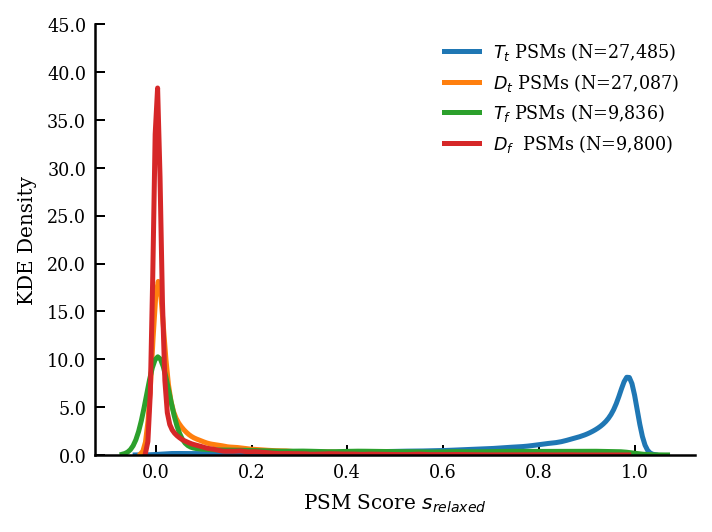

In [18]:
# PSM score distribution
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
scores_corr = df_sorted_psm[(df_sorted_psm['is_decoy'] == False) & (df_sorted_psm['denovo_label'] == 1)]['psm_score_relax'].to_numpy()
scores_false = df_sorted_psm[(df_sorted_psm['is_decoy'] == False) & (df_sorted_psm['denovo_label'] == 0)]['psm_score_relax'].to_numpy()
scores_decoy = df_sorted_psm[(df_sorted_psm['is_decoy'] == True) & (df_sorted_psm['denovo_label'] == 0)]['psm_score_relax'].to_numpy()
scores_decoy_true = df_sorted_psm[(df_sorted_psm['is_decoy'] == True) & (df_sorted_psm['denovo_label'] == 1)]['psm_score_relax'].to_numpy()
N_corr = len(scores_corr)
N_false = len(scores_false)
N_corr_d = len(scores_decoy)
N_false_d = len(scores_decoy_true)
print(len(scores_corr), len(scores_false), len(scores_decoy), len(scores_decoy_true))
plt.rcParams.update({
    "figure.dpi": 180,
    "savefig.dpi": 600,
    "font.size": 8,
    "font.family": "serif",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 1.0,
    "axes.labelsize": 10,
    "axes.titlesize": 14,
    "legend.frameon": False,
    "legend.fontsize": 8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 4,
    "ytick.major.size": 4,
})

print(len(scores_corr), len(scores_false), len(scores_decoy))
plt.figure(figsize=(4, 3))
sns.kdeplot(scores_corr, bw_adjust=0.5, label=f'$T_t$ PSMs (N={N_corr:,})', linewidth=2)
sns.kdeplot(scores_decoy_true, bw_adjust=0.5, label=f'$D_t$ PSMs (N={N_false_d:,})', linewidth=2)
sns.kdeplot(scores_false, bw_adjust=0.5, label=f'$T_f$ PSMs (N={N_false:,})', linewidth=2)
sns.kdeplot(scores_decoy, bw_adjust=0.5, label=f'$D_f$  PSMs (N={N_corr_d:,})', linewidth=2)
plt.legend(fontsize=7, loc='best')
plt.xticks(fontsize=7) 
current_ticks = plt.yticks()[0]
plt.yticks(
    ticks=current_ticks,
    fontsize=7,
    labels=[f'{tick:.1f}' for tick in current_ticks]  
)
plt.xlabel('PSM Score $s_{\mathit{relaxed}}$', fontsize=8)
plt.ylabel('KDE Density', fontsize=8)
plt.tight_layout()
plt.show()

27485 9836 9800 27087
27485 9836 9800


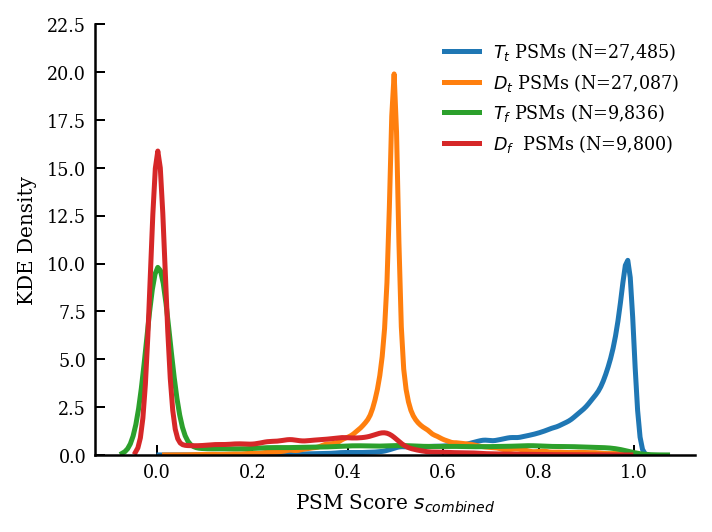

In [19]:
# PSM score distribution
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
scores_corr = df_sorted_psm[(df_sorted_psm['is_decoy'] == False) & (df_sorted_psm['denovo_label'] == 1)]['psm_score'].to_numpy()
scores_false = df_sorted_psm[(df_sorted_psm['is_decoy'] == False) & (df_sorted_psm['denovo_label'] == 0)]['psm_score'].to_numpy()
scores_decoy = df_sorted_psm[(df_sorted_psm['is_decoy'] == True) & (df_sorted_psm['denovo_label'] == 0)]['psm_score'].to_numpy()
scores_decoy_true = df_sorted_psm[(df_sorted_psm['is_decoy'] == True) & (df_sorted_psm['denovo_label'] == 1)]['psm_score'].to_numpy()
N_corr = len(scores_corr)
N_false = len(scores_false)
N_corr_d = len(scores_decoy)
N_false_d = len(scores_decoy_true)
print(len(scores_corr), len(scores_false), len(scores_decoy), len(scores_decoy_true))
plt.rcParams.update({
    "figure.dpi": 180,
    "savefig.dpi": 600,
    "font.size": 8,
    "font.family": "serif",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 1.0,
    "axes.labelsize": 10,
    "axes.titlesize": 14,
    "legend.frameon": False,
    "legend.fontsize": 8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 4,
    "ytick.major.size": 4,
})

print(len(scores_corr), len(scores_false), len(scores_decoy))
plt.figure(figsize=(4, 3))
sns.kdeplot(scores_corr, bw_adjust=0.5, label=f'$T_t$ PSMs (N={N_corr:,})', linewidth=2)
sns.kdeplot(scores_decoy_true, bw_adjust=0.5, label=f'$D_t$ PSMs (N={N_false_d:,})', linewidth=2)
sns.kdeplot(scores_false, bw_adjust=0.5, label=f'$T_f$ PSMs (N={N_false:,})', linewidth=2)
sns.kdeplot(scores_decoy, bw_adjust=0.5, label=f'$D_f$  PSMs (N={N_corr_d:,})', linewidth=2)
plt.legend(fontsize=7, loc='best')
plt.xticks(fontsize=7) 
current_ticks = plt.yticks()[0]
plt.yticks(
    ticks=current_ticks,
    fontsize=7,
    labels=[f'{tick:.1f}' for tick in current_ticks]  
)
plt.xlabel('PSM Score $s_{\mathit{combined}}$', fontsize=8)
plt.ylabel('KDE Density', fontsize=8)
plt.tight_layout()
plt.show()

In [20]:
df_sorted_psm, gamma_psm, conservative_point, optimal_idx, conservative_interval = gamma_fdr(df_sorted_psm, fdr_thresh=0.05)
print(gamma_psm, conservative_point, optimal_idx, conservative_interval)

conservative start point: 0.0442, target fdr: 0.0500, start idx: 25136
according to Adjustment-factor theorem: gamma=0.8254 (nearby target fdr)
conservative interval: interval[0.0502, 0.2636], gamma=0.8254
0.8254071661237785 0.050187709938747285 26839 [0.050187709938747285, 0.2635513517858578]


In [21]:
# filter psm 
df_filtered_psm = df_sorted_psm[df_sorted_psm['estimated_fdr_update'] <= fdr_threshold]
cutoff_score = min(df_filtered_psm['psm_score'].tolist())
print(cutoff_score, len(df_filtered_psm))

0.6904584765434265 26822


## 2.2 CCT-Peptide QC

In [22]:
key_cols = ['spectrum_idx', 'sample', 'psm_id', 'denovo_label']
df_sorted_psm = df_sorted_psm.set_index(key_cols)
df_filtered_psm = df_filtered_psm.set_index(key_cols)
df_candidates_pep = df_sorted_psm.loc[df_filtered_psm.index].reset_index()
df_filtered_psm = df_filtered_psm.reset_index()
df_sorted_psm = df_sorted_psm.reset_index()
df_candidates_pep

,spectrum_idx,sample,psm_id,denovo_label,aa_conf_mean,aa_conf_var,aa_conf_min,aa_conf_max,num_low_conf,num_high_conf,...,psm_score_strict,sequence,cum_decoy,cum_decoy_true,cum_decoy_false,cum_true,cum_false,estimated_fdr,observed_fdp,estimated_fdr_update
0,7389,A_Thaliana,7333,True,2.599619,0.131668,2.113962,3.213145,0.0,13.0,...,0.999776,YTENGMSEDLAYK,0,0,0,1,0,0.000000,0.000000,0.000000
1,7389,A_Thaliana,7333,True,2.268000,0.255179,1.536416,3.213145,0.0,13.0,...,0.999719,KYALDESMGNETY,9605,9195,410,26654,2098,0.334064,0.072969,0.275739
2,4984,C_Elegans,4984,True,2.840573,0.333767,1.835591,3.814333,0.0,9.0,...,0.999513,QLVENLIEK,0,0,0,2,0,0.000000,0.000000,0.000000
3,4984,C_Elegans,4984,True,2.596445,0.482467,1.090020,3.417492,0.0,9.0,...,0.998614,KEILNEVLQ,9505,9098,407,26652,2098,0.330609,0.072974,0.272887
4,8787,C_Elegans,8786,True,3.202156,0.361636,2.229316,3.904277,0.0,8.0,...,0.999560,KYELALNR,0,0,0,3,0,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53225,5781,C_Elegans,5781,True,1.578285,0.278190,0.925009,2.821595,0.0,11.0,...,0.942073,REVYHGNQHAW,20590,19926,664,26838,2211,0.708802,0.076113,0.585051
53226,5058,A_Thaliana,5023,True,2.307060,0.659674,0.102503,3.179285,1.0,11.0,...,0.948422,VLHVFTHHVVAK,1531,1468,63,24023,1267,0.060538,0.050099,0.049968
53227,5058,A_Thaliana,5023,True,1.812342,0.395442,0.494098,2.590854,0.0,11.0,...,0.983262,KAVVHHTFVHLV,4311,4095,216,25986,1838,0.154938,0.066058,0.127887
53228,5439,E_Coli,5417,True,2.083923,0.976540,0.778655,3.598696,0.0,13.0,...,0.758952,VILAGEVTTPVTVR,1532,1469,63,24024,1267,0.060575,0.050097,0.049999


In [23]:
df_pep = df_candidates_pep.sort_values('psm_score', ascending=False).drop_duplicates('sequence', keep='first')
df_pep

,spectrum_idx,sample,psm_id,denovo_label,aa_conf_mean,aa_conf_var,aa_conf_min,aa_conf_max,num_low_conf,num_high_conf,...,psm_score_strict,sequence,cum_decoy,cum_decoy_true,cum_decoy_false,cum_true,cum_false,estimated_fdr,observed_fdp,estimated_fdr_update
0,7389,A_Thaliana,7333,True,2.599619,0.131668,2.113962,3.213145,0.0,13.0,...,0.999776,YTENGMSEDLAYK,0,0,0,1,0,0.000000,0.000000,0.000000
2,4984,C_Elegans,4984,True,2.840573,0.333767,1.835591,3.814333,0.0,9.0,...,0.999513,QLVENLIEK,0,0,0,2,0,0.000000,0.000000,0.000000
4,8787,C_Elegans,8786,True,3.202156,0.361636,2.229316,3.904277,0.0,8.0,...,0.999560,KYELALNR,0,0,0,3,0,0.000000,0.000000,0.000000
6,6768,E_Coli,6739,True,2.565041,0.542174,1.114473,3.744932,0.0,12.0,...,0.999639,QYDINEAIALLK,0,0,0,4,0,0.000000,0.000000,0.000000
8,1957,E_Coli,1955,True,3.084198,0.557610,1.618688,4.503064,0.0,14.0,...,0.999423,ANEAYLQGQLGNPK,0,0,0,5,0,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45007,11332,C_Elegans,11330,True,1.684007,1.126952,0.000000,3.507023,1.0,7.0,...,0.392825,RFAPSC+57.021HAPVN,29904,26946,2958,27454,3374,0.970027,0.109446,0.800667
51984,590,E_Coli,590,True,1.601723,0.638581,0.574007,3.638203,0.0,18.0,...,0.315111,RTADVSEDVASLVEGVALSSAD,30042,26991,3051,27458,3431,0.972579,0.111075,0.802774
46440,5199,A_Thaliana,5161,False,2.178922,0.765195,0.593668,3.211560,0.0,6.0,...,0.356488,RYTNSFL,30051,26992,3059,27458,3436,0.972713,0.111219,0.802884
46592,9000,A_Thaliana,8937,True,1.475835,1.268266,0.000000,3.578620,2.0,7.0,...,0.296224,KVFLQNPDKVT,30130,27004,3126,27464,3467,0.974104,0.112088,0.804032


In [24]:
X_pep = df_pep[feature_name].to_numpy().tolist()
y_pep_relax = df_pep['class'].tolist()
y_pep_strict = df_pep['denovo_label'].tolist()

In [25]:
ckpt_path_pep_relax = f'MLP_model/{name}_{fdr_threshold}_pep_relax.pt'
ckpt_path_pep_strict = f'MLP_model/{name}_{fdr_threshold}_pep_strict.pt'
print(ckpt_path_pep_relax, ckpt_path_pep_strict)
# model_pep_relax = train_mlp(np.array(X_pep), y_pep_relax, lr=1e-3, dropout=0.0, epochs=50, batch_size=1024, device='cuda:0', ckpt_path=ckpt_path_pep_relax)
# model_pep_strict = train_mlp(np.array(X_pep), y_pep_strict, lr=1e-3, dropout=0.0, epochs=50, batch_size=1024, device='cuda:0', ckpt_path=ckpt_path_pep_strict)

MLP_model/xNovo_massive_0.05_pep_relax.pt MLP_model/xNovo_massive_0.05_pep_strict.pt


In [26]:
scores_pep_relax = test_mlp(np.array(X_pep), y_pep_relax, ckpt_path=ckpt_path_pep_relax)
scores_pep_strict = test_mlp(np.array(X_pep), y_pep_strict, ckpt_path=ckpt_path_pep_strict)

100%|██████████| 139/139 [00:00<00:00, 529.82it/s]



Final classification report (Val):
              precision    recall  f1-score   support

         0.0       0.94      0.91      0.93     18804
         1.0       0.90      0.94      0.92     16736

    accuracy                           0.92     35540
   macro avg       0.92      0.92      0.92     35540
weighted avg       0.92      0.92      0.92     35540



100%|██████████| 139/139 [00:00<00:00, 537.97it/s]



Final classification report (Val):
              precision    recall  f1-score   support

         0.0       0.92      0.66      0.77      2302
         1.0       0.98      1.00      0.99     33238

    accuracy                           0.97     35540
   macro avg       0.95      0.83      0.88     35540
weighted avg       0.97      0.97      0.97     35540



In [27]:
df_pep['pep_score'] = 0.5 * (scores_pep_relax+scores_pep_strict)
df_pep['pep_score_relax'] = scores_pep_relax
df_pep['pep_score_strict'] = scores_pep_strict
df_sorted_pep = calculate_fdr(df_pep.copy(), score_name='pep_score') 

In [28]:
df_pep_strict = calculate_fdr(df_pep, score_name='pep_score_strict')
df_pep_relax = calculate_fdr(df_pep, score_name='pep_score_relax')
df_pep_relax_adj, pep_relax_adj_best_gamma, pep_relax_adj_true_fdr, pep_relax_adj_optimal_idx, pep_relax_adj_best_interval = \
                    gamma_fdr(df_pep_relax.copy(), fdr_thresh=0.05)
df_pep_combined = calculate_fdr(df_pep, score_name='pep_score')
df_pep_adj, pep_adj_best_gamma, pep_adj_true_fdr, pep_adj_optimal_idx, pep_adj_best_interval = \
                    gamma_fdr(df_pep_combined.copy(), fdr_thresh=0.05)  

pep_fdr_strict, pep_score_strict, pep_true_strict = get_corss_point_fdr_curve(df_pep_strict, score_name='pep_score_strict')
pep_fdr_relax, pep_score_relax, pep_true_relax = get_corss_point_fdr_curve(df_pep_relax, score_name='pep_score_relax')
pep_fdr_relax_adj, pep_score_relax_adj, pep_true_relax_adj = get_corss_point_fdr_curve(df_pep_relax_adj, est_fdr_key='estimated_fdr_update',
                                                                                          score_name='pep_score_relax')
pep_fdr_combined, pep_score_combined, pep_true_combined = get_corss_point_fdr_curve(df_pep_combined, score_name='pep_score')
pep_fdr_adj, pep_score_adj, pep_true_adj = get_corss_point_fdr_curve(df_pep_adj, est_fdr_key='estimated_fdr_update', 
                                                                        score_name='pep_score')
print(pep_fdr_strict, pep_fdr_relax, pep_fdr_relax_adj, pep_fdr_combined, pep_fdr_adj)
print(pep_score_strict, pep_score_relax, pep_score_relax_adj, pep_score_combined, pep_score_adj)
print(pep_true_strict, pep_true_relax, pep_true_relax_adj, pep_true_combined, pep_true_adj)
print(pep_relax_adj_best_gamma, pep_relax_adj_true_fdr, pep_relax_adj_optimal_idx, pep_relax_adj_best_interval)
print(pep_adj_best_gamma, pep_adj_true_fdr, pep_adj_optimal_idx, pep_adj_best_interval)

conservative start point: 0.0584, target fdr: 0.0500, start idx: 17988
according to Adjustment-factor theorem: gamma=2.1676 (nearby target fdr)
conservative interval: interval[0.0502, 0.0648], gamma=2.1676
conservative start point: 0.0012, target fdr: 0.0500, start idx: 1662
gamma of interval: interval[0.0450, 0.0550], gamma=0.0584
conservative interval: interval[0.0450, 0.0550], gamma=0.0584
0.0 0.058425511885149446 0.05004919645785503 0.0012040939193257074 0.05009722353789961
0.9999978542327881 0.4051315188407898 0.7004133462905884 0.9957880973815918 0.4804092347621918
1 16004 14479 1659 16691
2.1676136363636362 0.050245982289275175 15596 [0.050245982289275175, 0.06481895395619133]
0.05842831433713257 0.045002287282708144 33226 [0.045002287282708144, 0.05501892334632548]


19125 16736


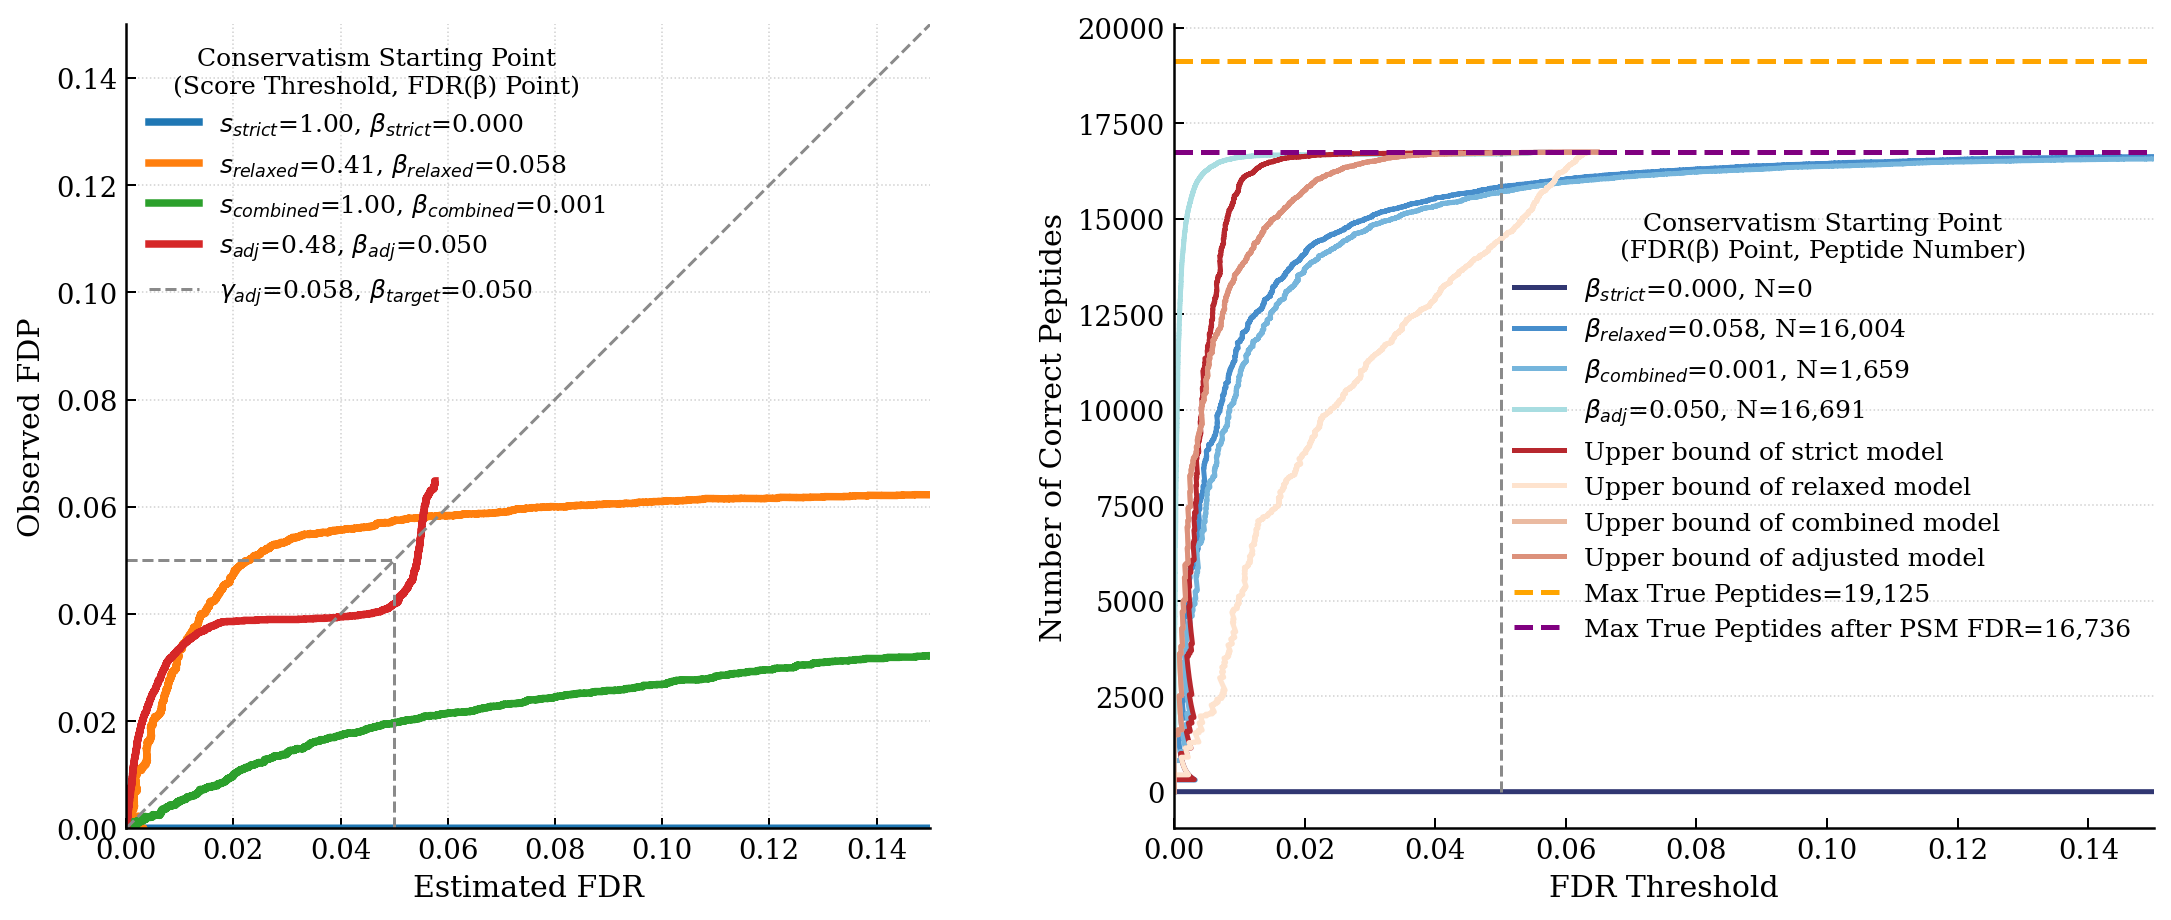

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
plt.rcParams.update({
    "figure.dpi": 180,
    "savefig.dpi": 600,
    "font.size": 8,
    "font.family": "serif",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 1.0,
    "axes.labelsize": 13,
    "axes.titlesize": 14,
    "legend.frameon": False,
    "legend.fontsize": 8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 4,
    "ytick.major.size": 4,
})

ideal_color = "#8a8a8a"

# ------------- 作图 -------------
fig, axs = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
# Panel A: Cumulative True FDR vs Cumulative Estimated FDR
axs[0].plot(
    df_pep_strict['estimated_fdr'].tolist(), df_pep_strict['observed_fdp'].tolist(),
    lw=3.0, label='$s_{\mathit{strict}}$='+f'{pep_score_strict:.2f}, '+'$β_{\mathit{strict}}$='+f'{pep_fdr_strict:.3f}'
)
axs[0].plot(
    df_pep_relax['estimated_fdr'].tolist(), df_pep_relax['observed_fdp'].tolist(),
    lw=3.0, label='$s_{\mathit{relaxed}}$='+f'{pep_score_relax:.2f}, '+'$β_{\mathit{relaxed}}$='+f'{pep_fdr_relax:.3f}'
)
axs[0].plot(
    df_pep_combined['estimated_fdr'].tolist(), df_pep_combined['observed_fdp'].tolist(),
    lw=3.0, label='$s_{\mathit{combined}}$='+f'{pep_score_combined:.2f}, '+'$β_{\mathit{combined}}$='+f'{pep_fdr_combined:.3f}'
)
axs[0].plot(
    df_pep_adj['estimated_fdr_update'].tolist(), df_pep_adj['observed_fdp'].tolist(),
    lw=3.0, label='$s_{\mathit{adj}}$='+f'{pep_score_adj:.2f}, '+'$β_{\mathit{adj}}$='+f'{pep_fdr_adj:.3f}'
)
axs[0].plot([0, 0.15], [0, 0.15], ls="--", lw=1.2, color=ideal_color, label='$γ_{\mathit{adj}}$='+f'{pep_adj_best_gamma:.3f}, '+'$β_{\mathit{target}}$='+f'{0.05:.3f}')
axs[0].plot([0, 0.05], [0.05, 0.05], ls="dashed", lw=1.2, color=ideal_color)
axs[0].plot([0.05, 0.05], [0, 0.05], ls="dashed", lw=1.2, color=ideal_color)

axs[0].set_xlim(0, 0.15)
axs[0].set_ylim(0, 0.15)
axs[0].tick_params(labelsize=11)
axs[0].set_aspect('equal', adjustable='box')  
axs[0].set_xlabel("Estimated FDR", fontsize=12)
axs[0].set_ylabel("Observed FDP", fontsize=12)
axs[0].grid(axis='both', linestyle=':', linewidth=0.6, alpha=0.6)
legend_obj = axs[0].legend(title='Conservatism Starting Point\n(Score Threshold, FDR(β) Point)', 
              loc="best", ncol=1, fontsize=10, frameon=False, title_fontsize=10)
legend_obj.get_title().set_horizontalalignment('center')

# Panel B: Cumulative counts vs Cumulative Estimated FDR
axs[1].plot(df_pep_strict['estimated_fdr'].tolist(), df_pep_strict['cum_true'].tolist(),
            label='$β_{\mathit{strict}}$='+f'{pep_fdr_strict:.3f}, N=0', lw=2.0, color='#313772')
axs[1].plot(df_pep_relax['estimated_fdr'].tolist(), df_pep_relax['cum_true'].tolist(),
            label='$β_{\mathit{relaxed}}$='+f'{pep_fdr_relax:.3f}, N={pep_true_relax:,}', lw=2.0, color='#478ecc')
axs[1].plot(df_pep_combined['estimated_fdr'].tolist(), df_pep_combined['cum_true'].tolist(),
            label='$β_{\mathit{combined}}$='+f'{pep_fdr_combined:.3f}, N={pep_true_combined:,}', lw=2.0, color='#75b5dc')
axs[1].plot(df_pep_adj['estimated_fdr_update'].tolist(), df_pep_adj['cum_true'].tolist(),
            label='$β_{\mathit{adj}}$='+f'{pep_fdr_adj:.3f}, N={pep_true_adj:,}', lw=2.0, color='#a8dde1')


axs[1].plot(df_pep_strict['observed_fdp'].tolist(), df_pep_strict['cum_true'].tolist(),
            label='Upper bound of strict model', lw=2.0, color='#b7282e')
axs[1].plot(df_pep_relax['observed_fdp'].tolist(), df_pep_relax['cum_true'].tolist(),
            label='Upper bound of relaxed model', lw=2.0, color='#fee3ce')
axs[1].plot(df_pep_combined['observed_fdp'].tolist(), df_pep_combined['cum_true'].tolist(),
            label='Upper bound of combined model', lw=2.0, color='#eabaa1')
axs[1].plot(df_pep_adj['observed_fdp'].tolist(), df_pep_adj['cum_true'].tolist(),
            label='Upper bound of adjusted model', lw=2.0, color='#dc917b')

axs[1].plot([0.05, 0.05], [0, max(df_sorted_pep['cum_true'].tolist())], ls="dashed", lw=1.2, color=ideal_color)

a = df_psm_strict.drop_duplicates('sequence')
max_peptides_number = sum(a[(a['denovo_label']==True)&(a['is_decoy']==False)]['denovo_label'])
max_peptides_number_after_PSM_FDR = max(df_pep_relax['cum_true'])
print(max_peptides_number, max_peptides_number_after_PSM_FDR)
axs[1].plot([0.0, 0.5], [max_peptides_number, max_peptides_number], ls="--", 
            label=f'Max True Peptides={max_peptides_number:,}', lw=2.0, color='orange')
axs[1].plot([0.0, 0.5], [max_peptides_number_after_PSM_FDR, max_peptides_number_after_PSM_FDR], ls="--", 
            label=f'Max True Peptides after PSM FDR={max_peptides_number_after_PSM_FDR:,}', lw=2.0, color='purple')

axs[1].set_xlim(0, 0.15)
axs[1].tick_params(labelsize=11)
axs[0].set_aspect('equal', adjustable='box') 
axs[1].set_xlabel("FDR Threshold", fontsize=12)
axs[1].set_ylabel("Number of Correct Peptides", fontsize=12)
axs[1].grid(axis='y', linestyle=':', linewidth=0.6, alpha=0.6)
legend_obj2 = axs[1].legend(title='Conservatism Starting Point\n(FDR(β) Point, Peptide Number)', loc="center right", ncol=1, fontsize=10,
                           frameon=False, title_fontsize=10)
legend_obj2.get_title().set_horizontalalignment('center')
plt.show()

19125 16736


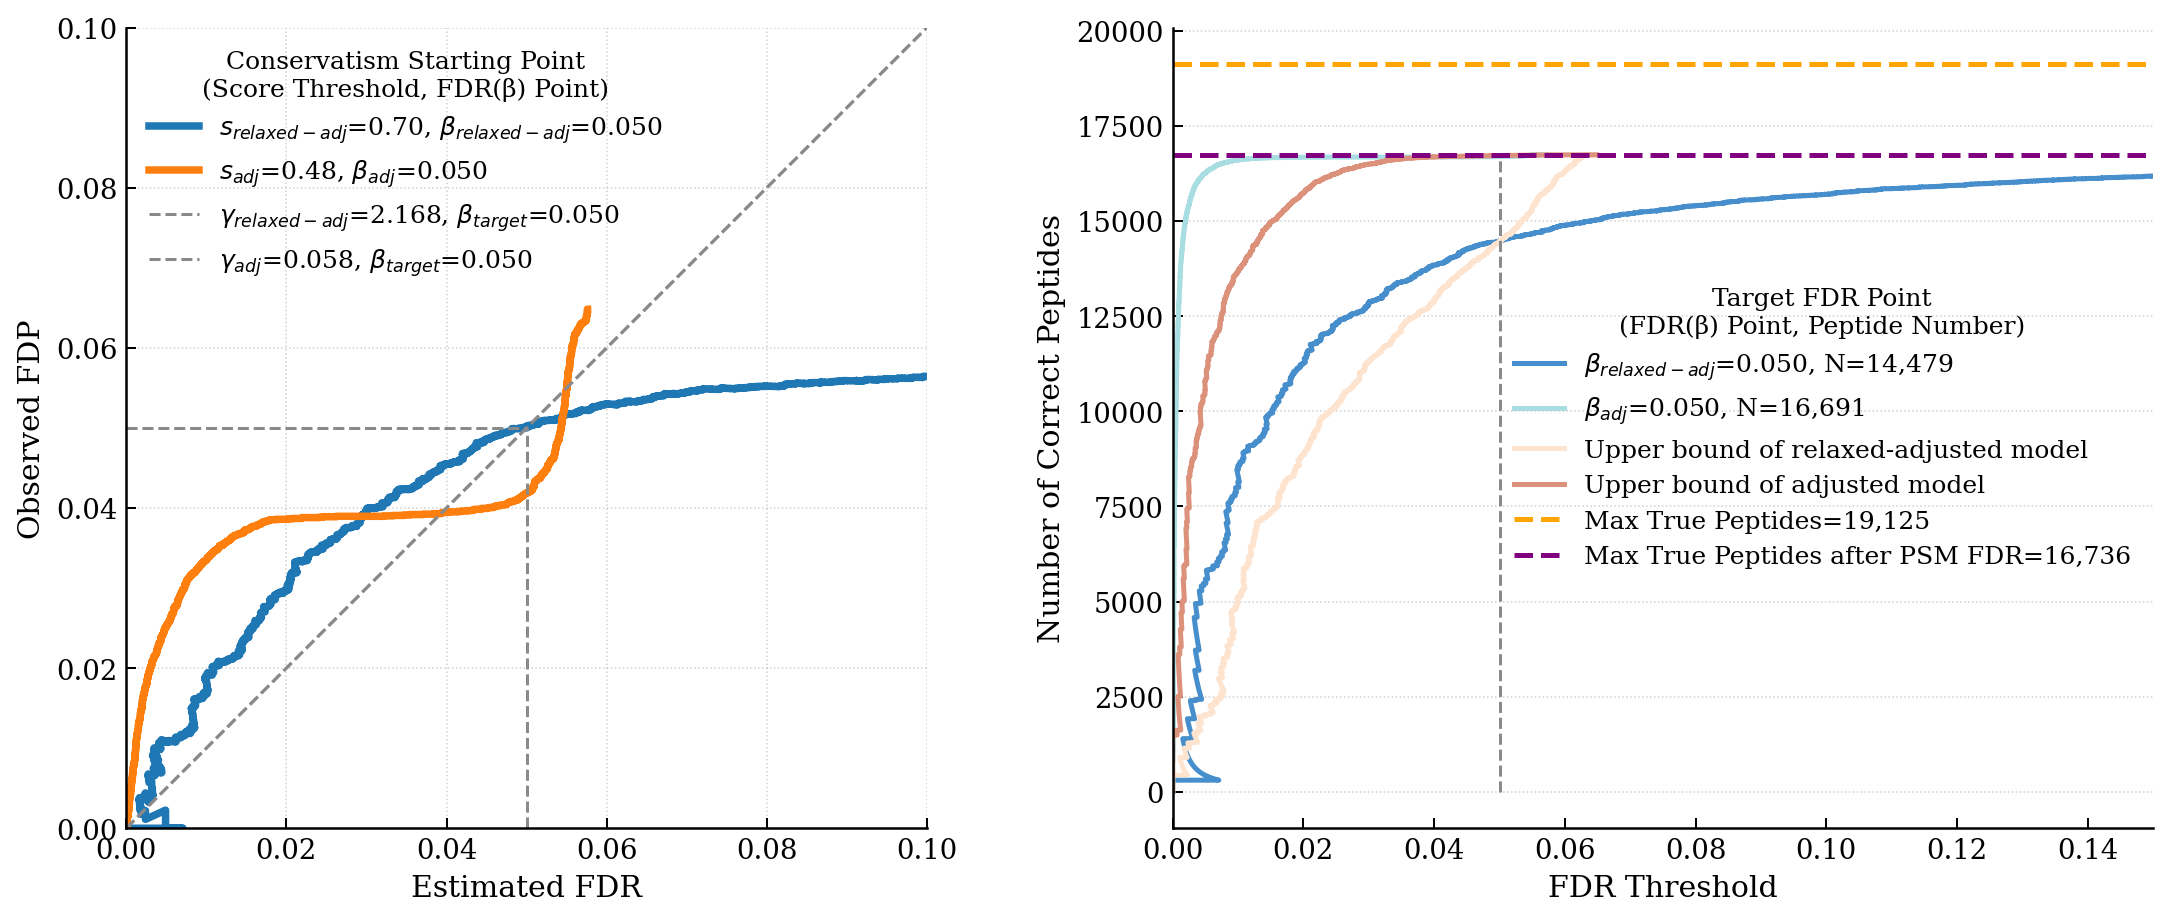

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
plt.rcParams.update({
    "figure.dpi": 180,
    "savefig.dpi": 600,
    "font.size": 8,
    "font.family": "serif",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 1.0,
    "axes.labelsize": 13,
    "axes.titlesize": 14,
    "legend.frameon": False,
    "legend.fontsize": 8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 4,
    "ytick.major.size": 4,
})

ideal_color = "#8a8a8a"

# ------------- 作图 -------------
fig, axs = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
# Panel A: Cumulative True FDR vs Cumulative Estimated FDR
axs[0].plot(
    df_pep_relax_adj['estimated_fdr_update'].tolist(), df_pep_relax_adj['observed_fdp'].tolist(),
    lw=3.0, label='$s_{\mathit{relaxed-adj}}$='+f'{pep_score_relax_adj:.2f}, '+'$β_{\mathit{relaxed-adj}}$='+f'{pep_fdr_relax_adj:.3f}'
)
axs[0].plot(
    df_pep_adj['estimated_fdr_update'].tolist(), df_pep_adj['observed_fdp'].tolist(),
    lw=3.0, label='$s_{\mathit{adj}}$='+f'{pep_score_adj:.2f}, '+'$β_{\mathit{adj}}$='+f'{pep_fdr_adj:.3f}'
)
# 理想线
axs[0].plot([0, 0.15], [0, 0.15], ls="--", lw=1.2, color=ideal_color, label='$γ_{\mathit{relaxed-adj}}$='+f'{pep_relax_adj_best_gamma:.3f}, '+'$β_{\mathit{target}}$='+f'{0.05:.3f}')
axs[0].plot([0, 0.15], [0, 0.15], ls="--", lw=1.2, color=ideal_color, label='$γ_{\mathit{adj}}$='+f'{pep_adj_best_gamma:.3f}, '+'$β_{\mathit{target}}$='+f'{0.05:.3f}')
axs[0].plot([0, 0.05], [0.05, 0.05], ls="dashed", lw=1.2, color=ideal_color)
axs[0].plot([0.05, 0.05], [0, 0.05], ls="dashed", lw=1.2, color=ideal_color)

axs[0].set_xlim(0, 0.1)
axs[0].set_ylim(0, 0.1)
axs[0].tick_params(labelsize=11)
axs[0].set_aspect('equal', adjustable='box') 
axs[0].set_xlabel("Estimated FDR", fontsize=12)
axs[0].set_ylabel("Observed FDP", fontsize=12)
axs[0].grid(axis='both', linestyle=':', linewidth=0.6, alpha=0.6)
legend_obj = axs[0].legend(title='Conservatism Starting Point\n(Score Threshold, FDR(β) Point)', 
              loc="upper left", ncol=1, fontsize=10, frameon=False, title_fontsize=10)
legend_obj.get_title().set_horizontalalignment('center')

# Panel B: Cumulative counts vs Cumulative Estimated FDR
axs[1].plot(df_pep_relax_adj['estimated_fdr_update'].tolist(), df_pep_relax_adj['cum_true'].tolist(),
            label='$β_{\mathit{relaxed-adj}}$='+f'{pep_fdr_relax_adj:.3f}, N={pep_true_relax_adj:,}', lw=2.0, color='#478ecc')
axs[1].plot(df_pep_adj['estimated_fdr_update'].tolist(), df_pep_adj['cum_true'].tolist(),
            label='$β_{\mathit{adj}}$='+f'{pep_fdr_adj:.3f}, N={pep_true_adj:,}', lw=2.0, color='#a8dde1')

axs[1].plot(df_pep_relax_adj['observed_fdp'].tolist(), df_pep_relax_adj['cum_true'].tolist(),
            label='Upper bound of relaxed-adjusted model', lw=2.0, color='#fee3ce')
axs[1].plot(df_pep_adj['observed_fdp'].tolist(), df_pep_adj['cum_true'].tolist(),
            label='Upper bound of adjusted model', lw=2.0, color='#dc917b')

axs[1].plot([0.05, 0.05], [0, max(df_sorted_pep['cum_true'].tolist())], ls="dashed", lw=1.2, color=ideal_color)

a = df_psm_strict.drop_duplicates('sequence')
max_peptides_number = sum(a[(a['denovo_label']==True)&(a['is_decoy']==False)]['denovo_label'])
max_peptides_number_after_PSM_FDR = max(df_pep_relax['cum_true'])
print(max_peptides_number, max_peptides_number_after_PSM_FDR)
axs[1].plot([0.0, 0.5], [max_peptides_number, max_peptides_number], ls="--", 
            label=f'Max True Peptides={max_peptides_number:,}', lw=2.0, color='orange')
axs[1].plot([0.0, 0.5], [max_peptides_number_after_PSM_FDR, max_peptides_number_after_PSM_FDR], ls="--", 
            label=f'Max True Peptides after PSM FDR={max_peptides_number_after_PSM_FDR:,}', lw=2.0, color='purple')

axs[1].set_xlim(0, 0.15)
axs[1].tick_params(labelsize=11)
axs[0].set_aspect('equal', adjustable='box')
axs[1].set_xlabel("FDR Threshold", fontsize=12)
axs[1].set_ylabel("Number of Correct Peptides", fontsize=12)
axs[1].grid(axis='y', linestyle=':', linewidth=0.6, alpha=0.6)
legend_obj2 = axs[1].legend(title='Target FDR Point\n(FDR(β) Point, Peptide Number)', loc="center right", ncol=1, fontsize=10,
                           frameon=False, title_fontsize=10)
legend_obj2.get_title().set_horizontalalignment('center')
plt.show()

In [31]:
df_sorted_pep, gamma_pep, conservative_point, optimal_idx, conservative_interval = gamma_fdr(df_sorted_pep)
print(gamma_pep, conservative_point, optimal_idx, conservative_interval)
df_sorted_pep

conservative start point: 0.0012, target fdr: 0.0500, start idx: 1662
gamma of interval: interval[0.0450, 0.0550], gamma=0.0584
conservative interval: interval[0.0450, 0.0550], gamma=0.0584
0.05842831433713257 0.045002287282708144 33226 [0.045002287282708144, 0.05501892334632548]


,spectrum_idx,sample,psm_id,denovo_label,aa_conf_mean,aa_conf_var,aa_conf_min,aa_conf_max,num_low_conf,num_high_conf,...,cum_decoy_true,cum_decoy_false,cum_true,cum_false,estimated_fdr,observed_fdp,estimated_fdr_update,pep_score,pep_score_relax,pep_score_strict
0,10113,C_Elegans,10111,True,3.025714,0.786818,1.578011,4.498103,0.0,7.0,...,0,0,1,0,0.000000,0.000000,0.000000,0.999792,0.999621,9.999626e-01
1,6610,E_Coli,6581,True,2.697487,0.371027,2.063623,4.513155,0.0,14.0,...,0,0,2,0,0.000000,0.000000,0.000000,0.999744,0.999882,9.996058e-01
2,5261,C_Elegans,5261,True,2.852988,0.434379,2.097077,4.506257,0.0,9.0,...,0,0,3,0,0.000000,0.000000,0.000000,0.999713,0.999778,9.996488e-01
3,3324,E_Coli,3311,True,3.121417,0.879589,1.769060,5.154425,0.0,11.0,...,0,0,4,0,0.000000,0.000000,0.000000,0.999671,0.999864,9.994789e-01
4,10376,C_Elegans,10374,True,3.244865,0.428634,2.098348,4.034511,0.0,11.0,...,0,0,5,0,0.000000,0.000000,0.000000,0.999667,0.999387,9.999473e-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35535,7396,A_Thaliana,7340,False,2.023517,0.352926,0.844964,2.947390,0.0,9.0,...,16502,1138,16736,1160,0.985695,0.064819,0.057593,0.000008,0.000016,2.299923e-27
35536,3969,E_Coli,3953,False,1.148944,0.195807,0.559693,1.747765,0.0,7.0,...,16502,1139,16736,1160,0.985751,0.064819,0.057596,0.000007,0.000014,1.204107e-28
35537,234,E_Coli,234,False,1.831209,0.198017,0.784043,2.506273,0.0,16.0,...,16502,1140,16736,1160,0.985807,0.064819,0.057599,0.000006,0.000013,3.786795e-30
35538,11957,A_Thaliana,11874,False,2.563194,0.757955,1.637046,4.469376,0.0,9.0,...,16502,1141,16736,1160,0.985863,0.064819,0.057602,0.000005,0.000011,1.012869e-30


16736 1160 1142 16502
16736 1160 1142


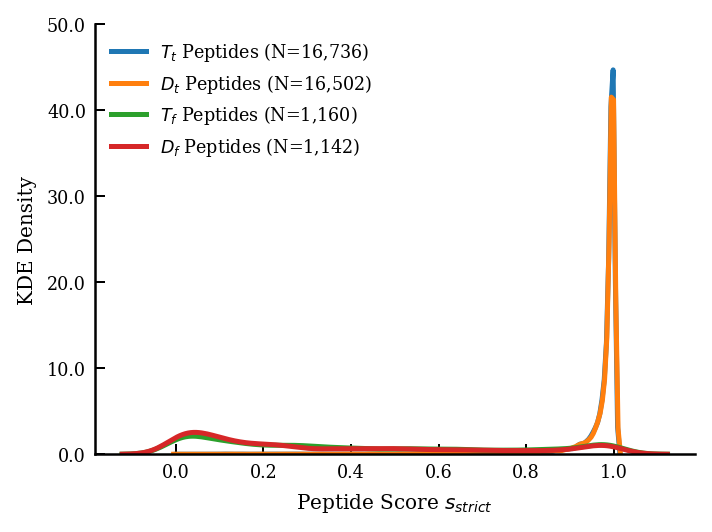

In [32]:
## Peptide score distribution
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from matplotlib.ticker import MultipleLocator, AutoMinorLocator, FormatStrFormatter
scores_corr = df_sorted_pep[(df_sorted_pep['is_decoy'] == False) & (df_sorted_pep['denovo_label'] == 1)]['pep_score_strict'].to_numpy()
scores_false = df_sorted_pep[(df_sorted_pep['is_decoy'] == False) & (df_sorted_pep['denovo_label'] == 0)]['pep_score_strict'].to_numpy()
scores_decoy = df_sorted_pep[(df_sorted_pep['is_decoy'] == True) & (df_sorted_pep['denovo_label'] == 0)]['pep_score_strict'].to_numpy()
scores_decoy_true = df_sorted_pep[(df_sorted_pep['is_decoy'] == True) & (df_sorted_pep['denovo_label'] == 1)]['pep_score_strict'].to_numpy()
N_corr = len(scores_corr)
N_false = len(scores_false)
N_corr_d = len(scores_decoy)
N_false_d = len(scores_decoy_true)
print(len(scores_corr), len(scores_false), len(scores_decoy), len(scores_decoy_true))
plt.rcParams.update({
    "figure.dpi": 180,
    "savefig.dpi": 600,
    "font.size": 8,
    "font.family": "serif",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 1.0,
    "axes.labelsize": 10,
    "axes.titlesize": 14,
    "legend.frameon": False,
    "legend.fontsize": 8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 4,
    "ytick.major.size": 4,
})

print(len(scores_corr), len(scores_false), len(scores_decoy))
plt.figure(figsize=(4, 3))
sns.kdeplot(scores_corr, bw_adjust=0.5, label=f'$T_t$ Peptides (N={N_corr:,})', linewidth=2)
sns.kdeplot(scores_decoy_true, bw_adjust=0.5, label=f'$D_t$ Peptides (N={N_false_d:,})', linewidth=2)
sns.kdeplot(scores_false, bw_adjust=0.5, label=f'$T_f$ Peptides (N={N_false:,})', linewidth=2)
sns.kdeplot(scores_decoy, bw_adjust=0.5, label=f'$D_f$ Peptides (N={N_corr_d:,})', linewidth=2)

plt.legend(fontsize=7, loc='best')
plt.xticks(fontsize=7)  
current_ticks = plt.yticks()[0]
plt.yticks(
    ticks=current_ticks,
    fontsize=7,
    labels=[f'{tick:.1f}' for tick in current_ticks] 
)
plt.xlabel('Peptide Score $s_{\mathit{strict}}$', fontsize=8)
plt.ylabel('KDE Density', fontsize=8)
plt.tight_layout()
plt.show()

16736 1160 1142 16502
16736 1160 1142


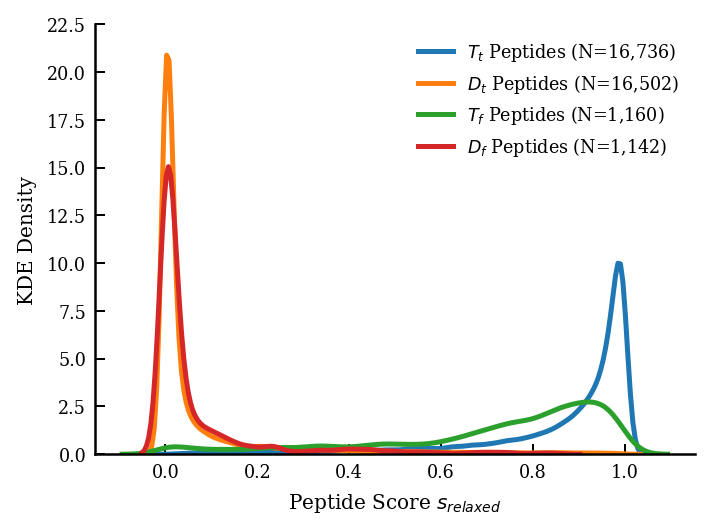

In [33]:
## Peptide score distribution
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from matplotlib.ticker import MultipleLocator, AutoMinorLocator, FormatStrFormatter
scores_corr = df_sorted_pep[(df_sorted_pep['is_decoy'] == False) & (df_sorted_pep['denovo_label'] == 1)]['pep_score_relax'].to_numpy()
scores_false = df_sorted_pep[(df_sorted_pep['is_decoy'] == False) & (df_sorted_pep['denovo_label'] == 0)]['pep_score_relax'].to_numpy()
scores_decoy = df_sorted_pep[(df_sorted_pep['is_decoy'] == True) & (df_sorted_pep['denovo_label'] == 0)]['pep_score_relax'].to_numpy()
scores_decoy_true = df_sorted_pep[(df_sorted_pep['is_decoy'] == True) & (df_sorted_pep['denovo_label'] == 1)]['pep_score_relax'].to_numpy()
N_corr = len(scores_corr)
N_false = len(scores_false)
N_corr_d = len(scores_decoy)
N_false_d = len(scores_decoy_true)
print(len(scores_corr), len(scores_false), len(scores_decoy), len(scores_decoy_true))
plt.rcParams.update({
    "figure.dpi": 180,
    "savefig.dpi": 600,
    "font.size": 8,
    "font.family": "serif",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 1.0,
    "axes.labelsize": 10,
    "axes.titlesize": 14,
    "legend.frameon": False,
    "legend.fontsize": 8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 4,
    "ytick.major.size": 4,
})

print(len(scores_corr), len(scores_false), len(scores_decoy))
plt.figure(figsize=(4, 3))
sns.kdeplot(scores_corr, bw_adjust=0.5, label=f'$T_t$ Peptides (N={N_corr:,})', linewidth=2)
sns.kdeplot(scores_decoy_true, bw_adjust=0.5, label=f'$D_t$ Peptides (N={N_false_d:,})', linewidth=2)
sns.kdeplot(scores_false, bw_adjust=0.5, label=f'$T_f$ Peptides (N={N_false:,})', linewidth=2)
sns.kdeplot(scores_decoy, bw_adjust=0.5, label=f'$D_f$ Peptides (N={N_corr_d:,})', linewidth=2)

plt.legend(fontsize=7, loc='best')
plt.xticks(fontsize=7)  
current_ticks = plt.yticks()[0]
plt.yticks(
    ticks=current_ticks,
    fontsize=7,
    labels=[f'{tick:.1f}' for tick in current_ticks] 
)
plt.xlabel('Peptide Score $s_{\mathit{relaxed}}$', fontsize=8)
plt.ylabel('KDE Density', fontsize=8)
plt.tight_layout()
plt.show()

16736 1160 1142 16502
16736 1160 1142


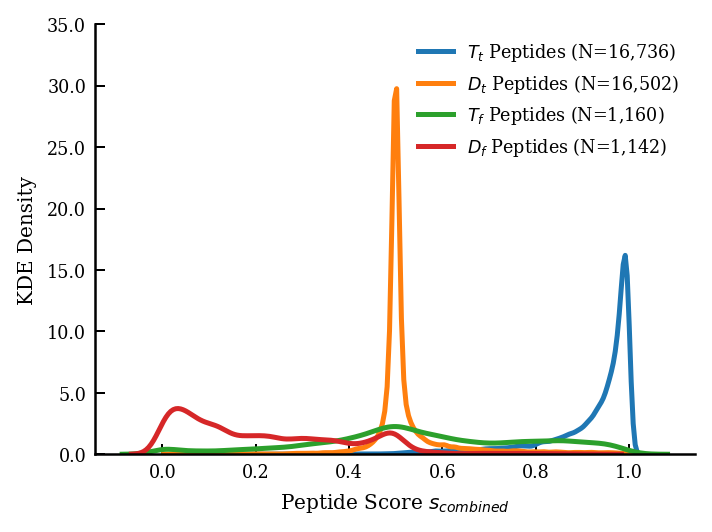

In [34]:
## Peptide score distribution
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from matplotlib.ticker import MultipleLocator, AutoMinorLocator, FormatStrFormatter
scores_corr = df_sorted_pep[(df_sorted_pep['is_decoy'] == False) & (df_sorted_pep['denovo_label'] == 1)]['pep_score'].to_numpy()
scores_false = df_sorted_pep[(df_sorted_pep['is_decoy'] == False) & (df_sorted_pep['denovo_label'] == 0)]['pep_score'].to_numpy()
scores_decoy = df_sorted_pep[(df_sorted_pep['is_decoy'] == True) & (df_sorted_pep['denovo_label'] == 0)]['pep_score'].to_numpy()
scores_decoy_true = df_sorted_pep[(df_sorted_pep['is_decoy'] == True) & (df_sorted_pep['denovo_label'] == 1)]['pep_score'].to_numpy()
N_corr = len(scores_corr)
N_false = len(scores_false)
N_corr_d = len(scores_decoy)
N_false_d = len(scores_decoy_true)
print(len(scores_corr), len(scores_false), len(scores_decoy), len(scores_decoy_true))
plt.rcParams.update({
    "figure.dpi": 180,
    "savefig.dpi": 600,
    "font.size": 8,
    "font.family": "serif",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 1.0,
    "axes.labelsize": 10,
    "axes.titlesize": 14,
    "legend.frameon": False,
    "legend.fontsize": 8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 4,
    "ytick.major.size": 4,
})

print(len(scores_corr), len(scores_false), len(scores_decoy))
plt.figure(figsize=(4, 3))
sns.kdeplot(scores_corr, bw_adjust=0.5, label=f'$T_t$ Peptides (N={N_corr:,})', linewidth=2)
sns.kdeplot(scores_decoy_true, bw_adjust=0.5, label=f'$D_t$ Peptides (N={N_false_d:,})', linewidth=2)
sns.kdeplot(scores_false, bw_adjust=0.5, label=f'$T_f$ Peptides (N={N_false:,})', linewidth=2)
sns.kdeplot(scores_decoy, bw_adjust=0.5, label=f'$D_f$ Peptides (N={N_corr_d:,})', linewidth=2)

plt.legend(fontsize=7, loc='best')
plt.xticks(fontsize=7)  
current_ticks = plt.yticks()[0]
plt.yticks(
    ticks=current_ticks,
    fontsize=7,
    labels=[f'{tick:.1f}' for tick in current_ticks] 
)
plt.xlabel('Peptide Score $s_{\mathit{combined}}$', fontsize=8)
plt.ylabel('KDE Density', fontsize=8)
plt.tight_layout()
plt.show()